# Confidence analysis
## Three run-1 models: ResNet18 224, ResNet50 28 and original ViT; full test split

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

threshold, n_bins = 0.90, 10
model_names = ['resnet18', 'resnet50', 'vit']
class_names = list(json.loads(Path('data/metadata.json').read_text())['label'].values())
class_names[3] = 'immature granulocytes'
with np.load('data/bloodmnist.npz', allow_pickle=False) as data:
    images, labels = data['test_images'], data['test_labels'].ravel()
probabilities = []
for name in model_names:
    rows = np.loadtxt(f'predictions/{name}_test.csv', delimiter=',', skiprows=1)
    np.testing.assert_array_equal(rows[:, 0], np.arange(len(labels)))
    np.testing.assert_array_equal(rows[:, 1], labels)
    probabilities.append(rows[:, 3:])
probabilities = np.stack(probabilities)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
predicted = probabilities.argmax(-1)
confidence = probabilities.max(-1)
correct = predicted == labels
bins = np.linspace(0, 1, n_bins + 1)
centers = (bins[:-1] + bins[1:]) / 2

def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -(p * np.log(np.maximum(p, 1e-300))).sum(-1) / np.log(p.shape[-1])

uncertainty = entropy(probabilities)
print(f'{len(labels)} test images; high-confidence threshold: {threshold:.0%}')
from itertools import combinations
pairs = list(combinations(range(len(model_names)), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)


3421 test images; high-confidence threshold: 90%


## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


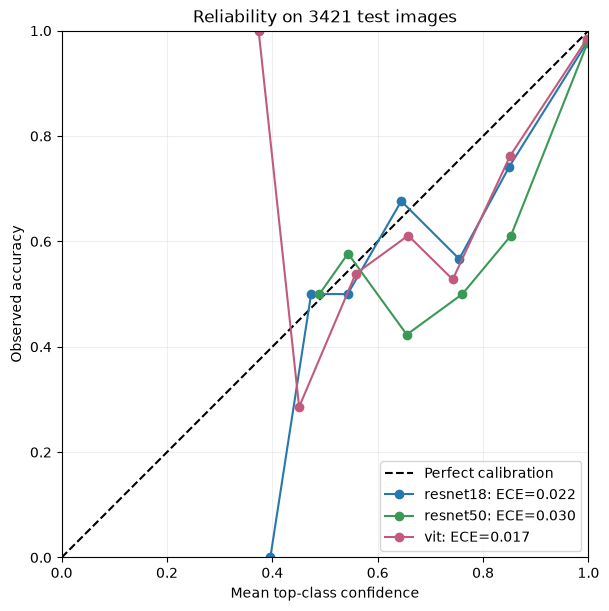

In [3]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

Mean confidence exceeds accuracy by about 2.1 percentage points for ResNet18, 2.9 for ResNet50 and 1.6 for ViT. These averages and the reliability curves indicate overconfidence, but do not identify its training-time cause. The fixed bins are descriptive; calibration quality should be checked on separate data before using confidence to guide decisions.

## Top-class confidence — all models overlaid, aggregated across classes; all correct and all incorrect test predictions

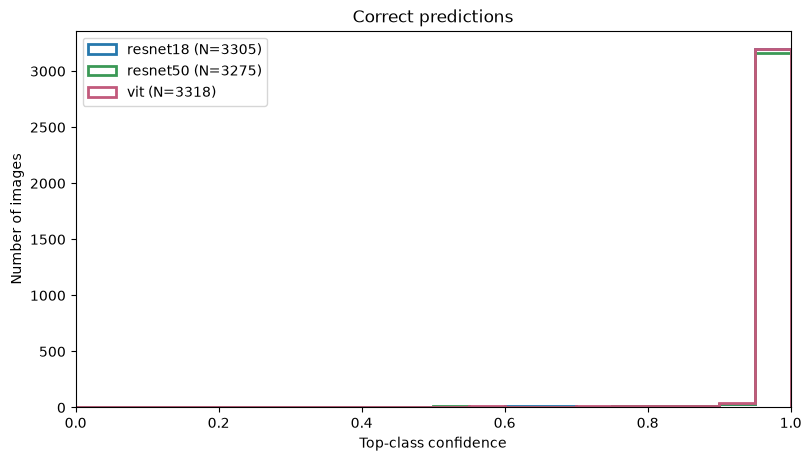

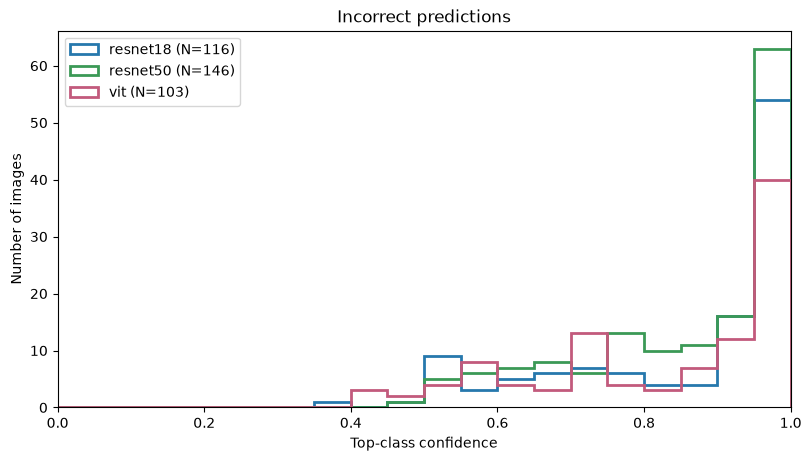

In [4]:
for is_correct, title in [(True, 'Correct predictions'), (False, 'Incorrect predictions')]:
    fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
    for m, color in enumerate(model_colors):
        mask = correct[m] == is_correct
        ax.hist(confidence[m, mask], bins=np.linspace(0, 1, 21), histtype='step',
                linewidth=2, color=color, label=f'{model_names[m]} (N={mask.sum()})')
    ax.set(title=title, xlabel='Top-class confidence', ylabel='Number of images', xlim=(0, 1))
    ax.legend()
    plt.show()

All three tested models appear overconfident: their mean confidence exceeds test accuracy, and some incorrect predictions remain highly confident. The plots do not tell us whether calibration-aware training was used. If these scores are displayed as trustworthy probabilities, they can mislead users, especially in high-risk applications. Calibration should therefore be checked and, if needed, fitted on separate validation data before the scores are shown to users.

## Confidence disagreement — each model's own maximum probability, not necessarily the same class

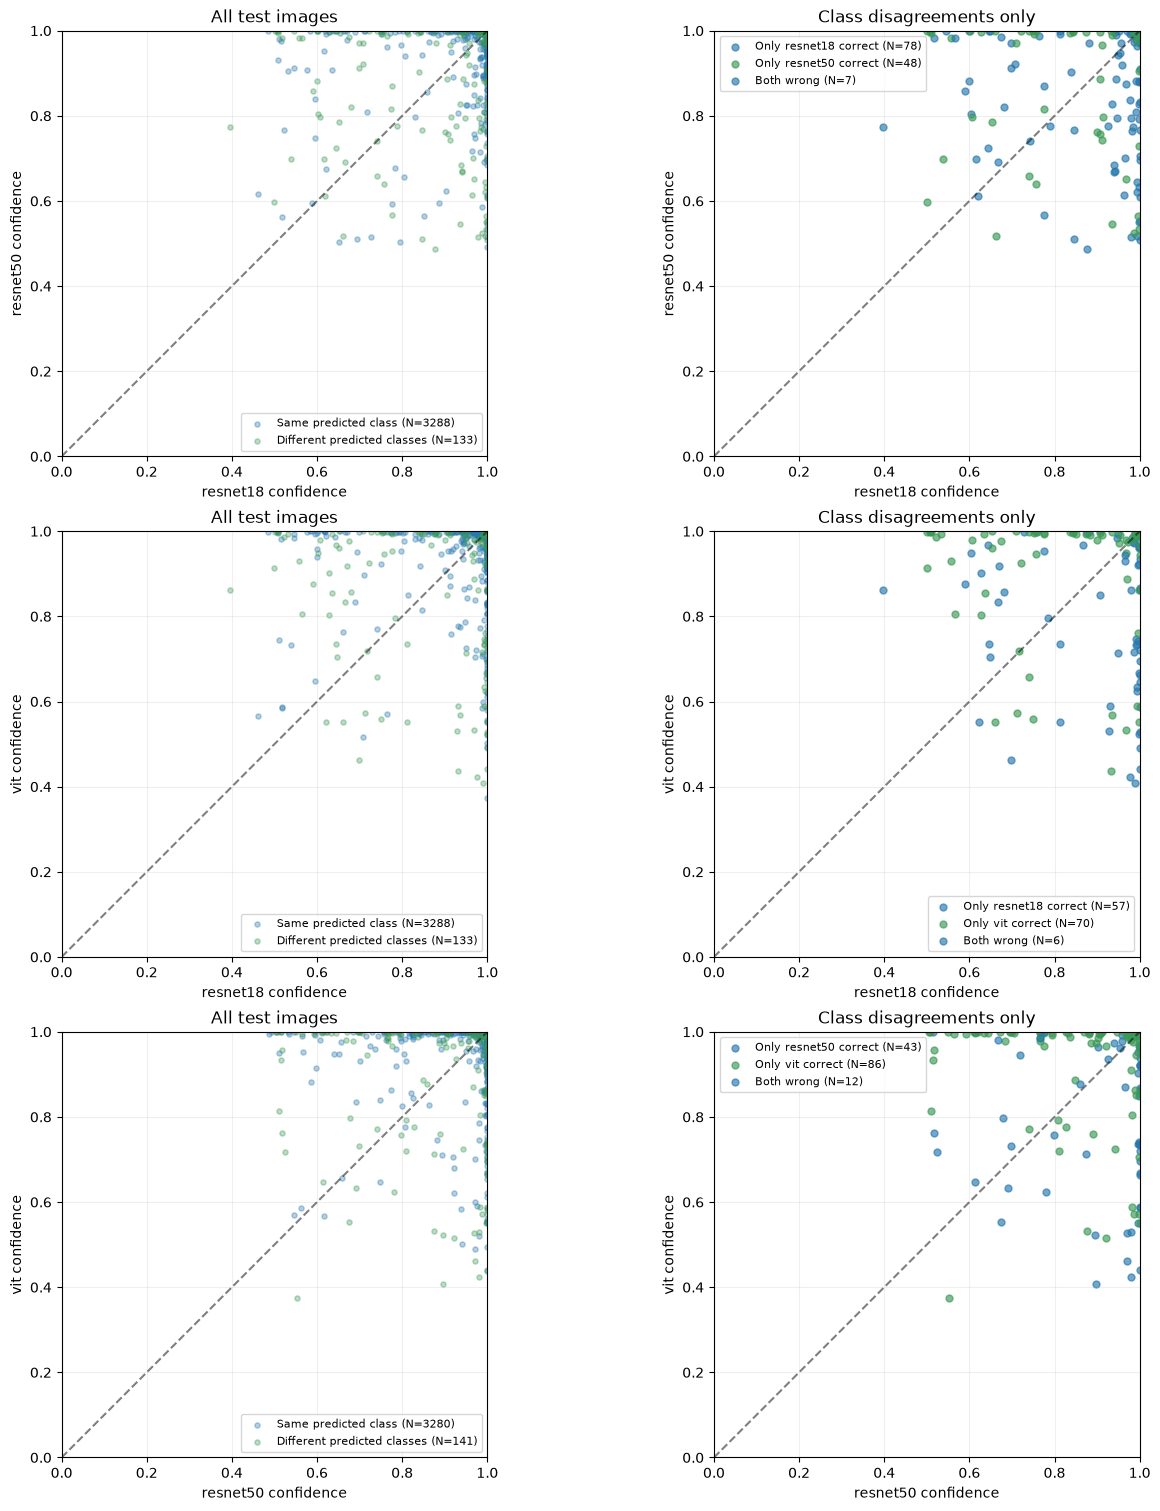

In [5]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 5 * len(pairs)), layout='constrained')
for row, (i, j) in enumerate(pairs):
    agree = predicted[i] == predicted[j]
    for mask, color, title in [(agree, 'C0', 'Same predicted class'), (~agree, 'C1', 'Different predicted classes')]:
        axes[row, 0].scatter(confidence[i, mask], confidence[j, mask], s=14, alpha=0.35,
                              color=color, label=f'{title} (N={mask.sum()})')
    groups = [(correct[i] & ~correct[j], 'C0', f'Only {model_names[i]} correct'),
              (~correct[i] & correct[j], 'C1', f'Only {model_names[j]} correct'),
              (~correct[i] & ~correct[j], 'C3', 'Both wrong')]
    for mask, color, title in groups:
        mask = mask & ~agree
        axes[row, 1].scatter(confidence[i, mask], confidence[j, mask], s=25, alpha=0.65,
                              color=color, label=f'{title} (N={mask.sum()})')
    for ax, title in zip(axes[row], ['All test images', 'Class disagreements only']):
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        ax.set(title=title, xlabel=f'{model_names[i]} confidence', ylabel=f'{model_names[j]} confidence',
               xlim=(0, 1), ylim=(0, 1))
        ax.set_aspect('equal')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
plt.show()


The models sometimes give different labels while both remain highly confident, so their scores do not automatically resolve disagreement. On disagreement cases, choosing the more confident model is correct in only about 59–65% of cases across the three pairs. This suggests that an ensemble needs a tested decision rule rather than simply trusting the largest score.

## Predictive entropy — normalized to [0, 1]; correct/error distributions and empirical error rate by entropy bin, with image counts

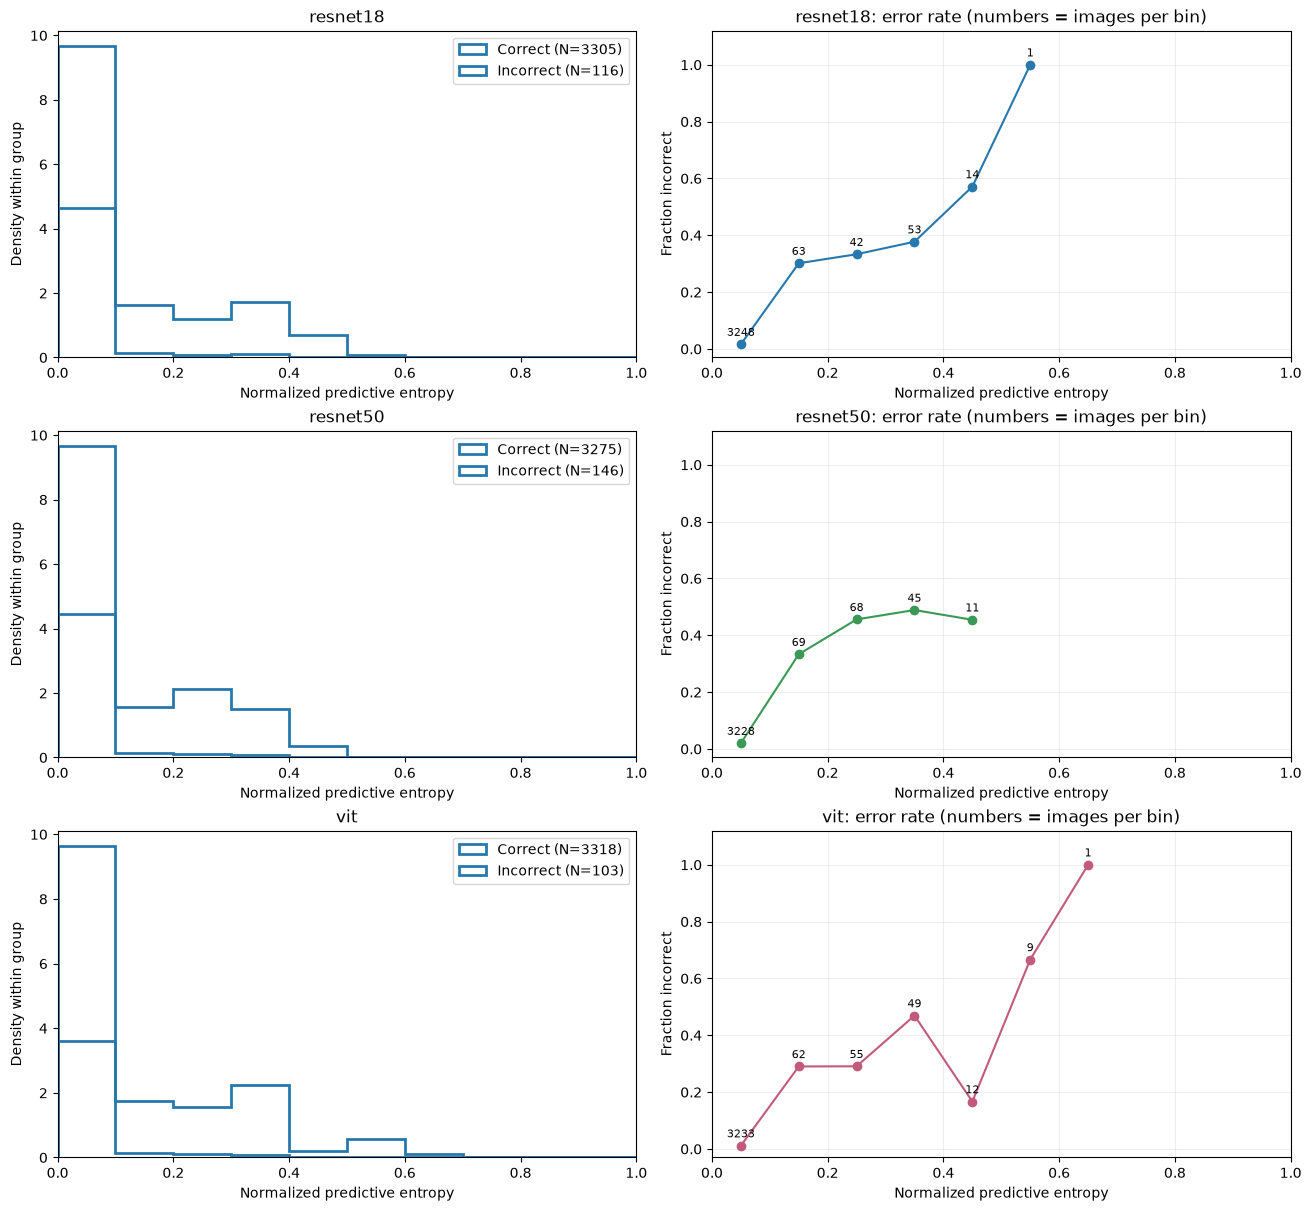

In [6]:
fig, axes = plt.subplots(len(model_names), 2, figsize=(13, 4 * len(model_names)), layout='constrained')
for m, name in enumerate(model_names):
    for mask, color, title in [(correct[m], 'C0', 'Correct'), (~correct[m], 'C3', 'Incorrect')]:
        if mask.any():
            axes[m, 0].hist(uncertainty[m, mask], bins=bins, density=True, histtype='step',
                            linewidth=2, color=color, label=f'{title} (N={mask.sum()})')
    axes[m, 0].set(title=name, xlabel='Normalized predictive entropy', ylabel='Density within group', xlim=(0, 1))
    axes[m, 0].legend()
    groups = bin_ids(uncertainty[m])
    counts = np.bincount(groups, minlength=n_bins)
    errors = np.bincount(groups, weights=~correct[m], minlength=n_bins)
    rates = np.divide(errors, counts, out=np.full(n_bins, np.nan), where=counts > 0)
    axes[m, 1].plot(centers, rates, 'o-', color=f'C{m}')
    for x, y, n in zip(centers, rates, counts):
        if n:
            axes[m, 1].annotate(str(n), (x, y), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8)
    axes[m, 1].set(title=f'{name}: error rate (numbers = images per bin)',
                   xlabel='Normalized predictive entropy', ylabel='Fraction incorrect', xlim=(0, 1), ylim=(-0.03, 1.12))
    axes[m, 1].grid(alpha=0.2)
plt.show()

Errors have higher average entropy, but 47% of ResNet18 errors, 45% of ResNet50 errors and 36% of ViT errors still have normalized entropy below 0.1. Low entropy therefore means a concentrated prediction, not necessarily a correct one. The error-rate curves support using uncertainty as a warning signal, while the small counts in some bins limit how reliable any particular threshold would be.

## Confidence under transformations — same 320-image stability subset; average noise repeats within each image; dashed lines show baseline

The absolute mean-confidence panel is omitted because the change panel contains the same curve shifted by its baseline. The remaining views distinguish score movement, confident errors and the spread of the full class distribution.

In [7]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['model_names'], model_names)
    indices, stability_labels = saved['indices'], saved['labels']
    baseline = saved['baseline']
    levels = {key[7:]: saved[key] for key in saved.files if key.startswith('levels_')}
    transformed = {kind: saved[kind] for kind in levels}
np.testing.assert_array_equal(stability_labels, labels[indices])
np.testing.assert_allclose(baseline, probabilities[:, indices], atol=1e-9)
base_confidence = baseline.max(-1)
base_entropy = entropy(baseline)
base_high_wrong = (baseline.argmax(-1) != stability_labels) & (base_confidence >= threshold)
confidence_changes = {}
def plot_confidence_change(kind, p):
    conf = p.max(-1)
    high_wrong = (p.argmax(-1) != stability_labels) & (conf >= threshold)
    metrics = {
        'Change in top-class confidence': (conf - base_confidence[:, None, None, :]).mean(axis=2),
        f'Wrong with confidence ≥ {threshold:.0%} (all images)': high_wrong.mean(axis=2),
        'Normalized predictive entropy': entropy(p).mean(axis=2),
    }
    confidence_changes[kind] = metrics
    references = [np.zeros(len(model_names)), base_high_wrong.mean(-1), base_entropy.mean(-1)]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), layout='constrained')
    reference = 1 if kind.endswith('_scale') or kind == 'brightness' else 0
    for ax, (title, values), original in zip(axes, metrics.items(), references):
        for m, name in enumerate(model_names):
            line, = ax.plot(levels[kind], values[m].mean(-1), 'o-', label=name)
            ax.axhline(original[m], color=line.get_color(), ls='--', alpha=0.4)
        ax.axvline(reference, color='gray', ls=':', alpha=0.5)
        ax.set(title=title, xlabel=kind)
        ax.grid(alpha=0.2)
    axes[0].legend()
    fig.suptitle(f'{kind} · N={len(stability_labels)} · confidence may increase even when predictions become wrong')
    plt.show()

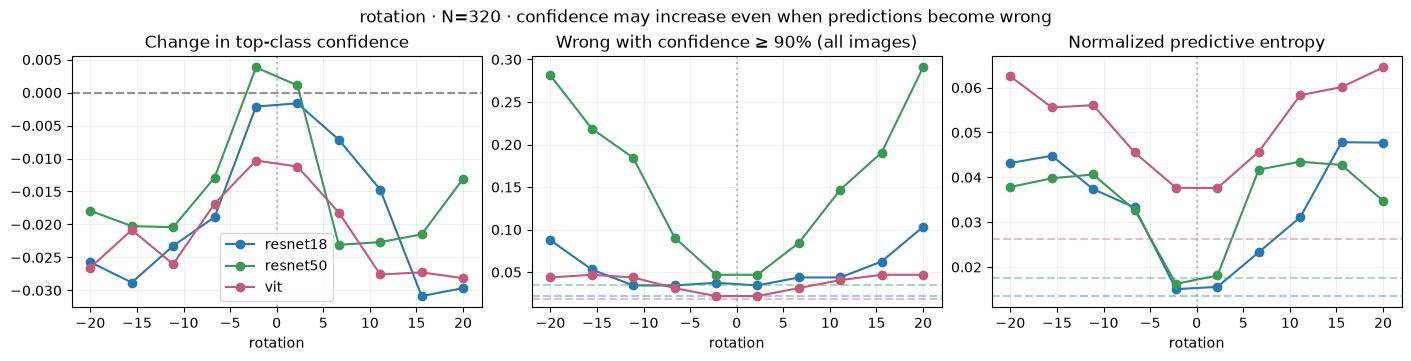

In [8]:
plot_confidence_change('rotation', transformed['rotation'])

For ResNet50, high-confidence errors account for 15.8% of image–rotation pairs, while its mean top-confidence falls by only 1.5 percentage points. The model often replaces one confident decision with another rather than clearly signaling uncertainty. Users would therefore receive little warning from the top score alone that rotation has made predictions less reliable.

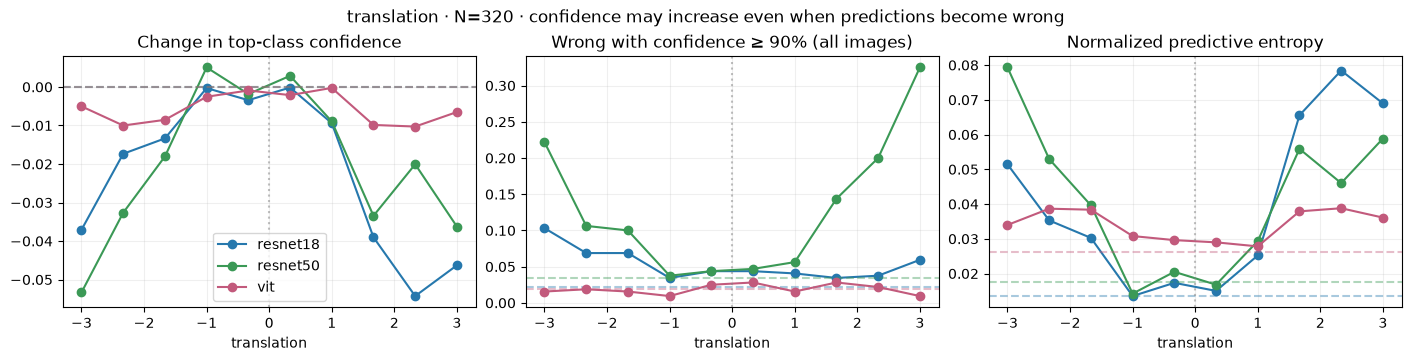

In [9]:
plot_confidence_change('translation', transformed['translation'])

Under translation, ResNet50 produces high-confidence errors on 12.8% of image–level pairs despite a mean confidence decrease of only 2.0 percentage points. ViT has a much smaller high-confidence-error fraction of 1.9% on the same inputs. This makes the error fraction more informative than a small average confidence change when assessing the practical effect of these shifts.

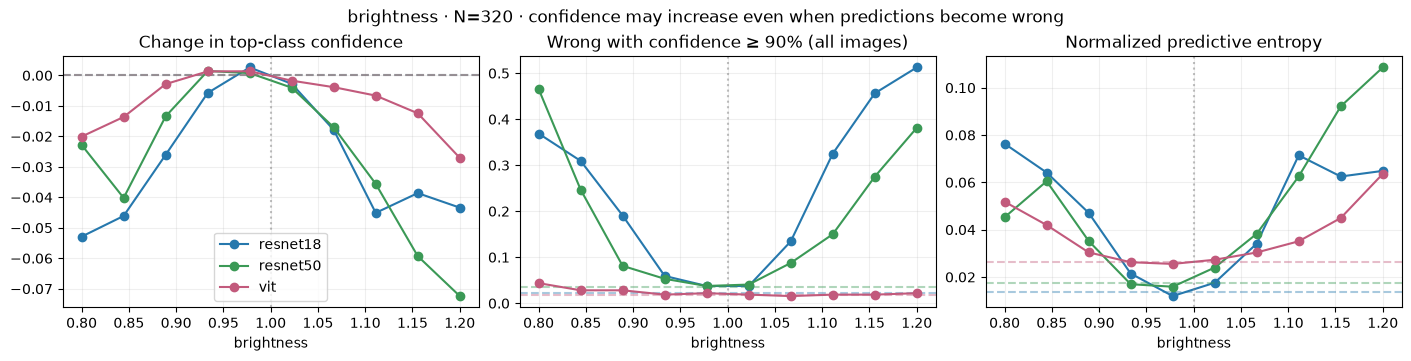

In [10]:
plot_confidence_change('brightness', transformed['brightness'])

Brightness changes create high-confidence errors on 24.3% of pairs for ResNet18 and 18.2% for ResNet50, compared with 2.3% for ViT. The CNN confidence scores fall only slightly while their correctness deteriorates substantially. A user could therefore see a reassuring score on an image whose changed brightness has strongly affected the decision.

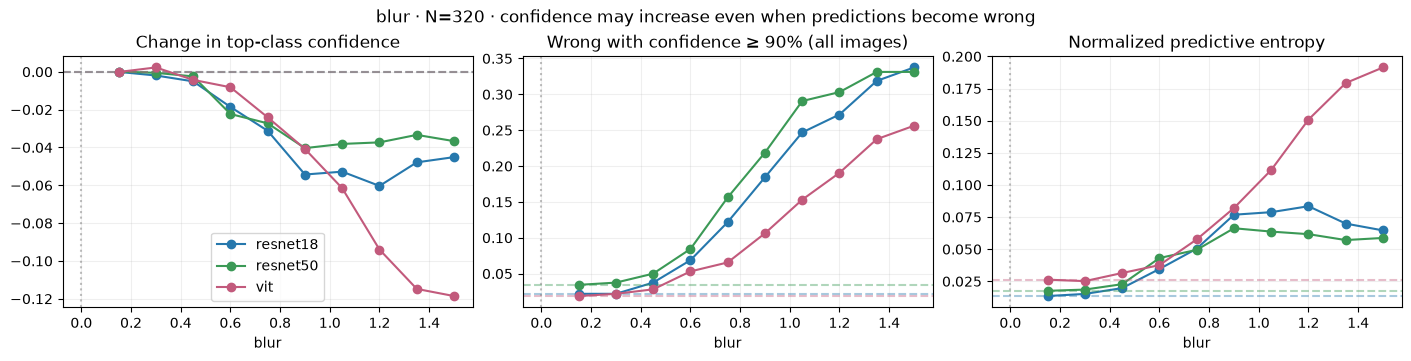

In [11]:
plot_confidence_change('blur', transformed['blur'])

Blur raises predictive entropy, particularly for ViT, so some information loss is reflected in a broader class distribution. However, high-confidence errors still occur: their fractions averaged over levels are 16.3%, 18.4% and 11.3% for ResNet18, ResNet50 and ViT. Higher average uncertainty is therefore not the same as reliably identifying every blurred image that will be misclassified.

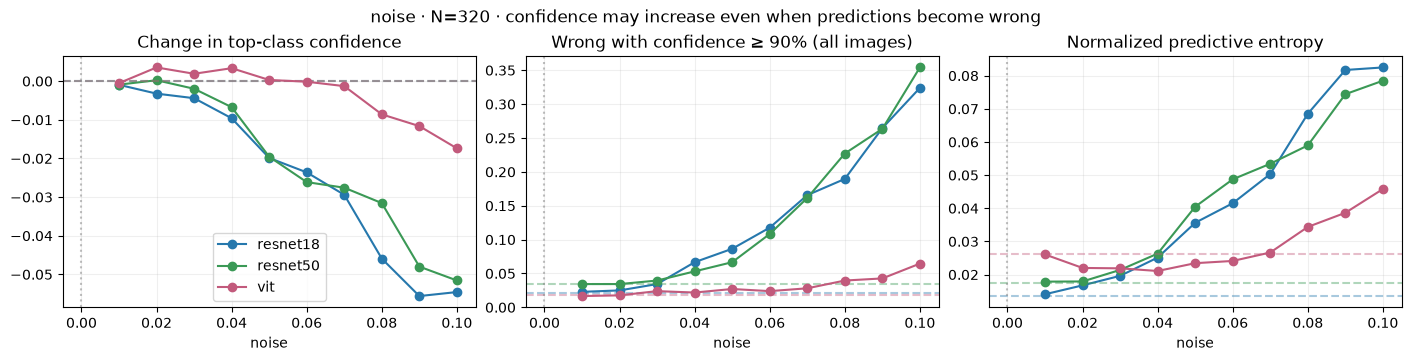

In [12]:
plot_confidence_change('noise', transformed['noise'])

ViT mean confidence decreases by only about 0.3 percentage points across the noise grid, yet it still produces high-confidence errors on 3.1% of pairs. Both CNNs have substantially larger high-confidence-error fractions of about 13%. This suggests that tolerating noise and knowing when a prediction is wrong are separate properties.

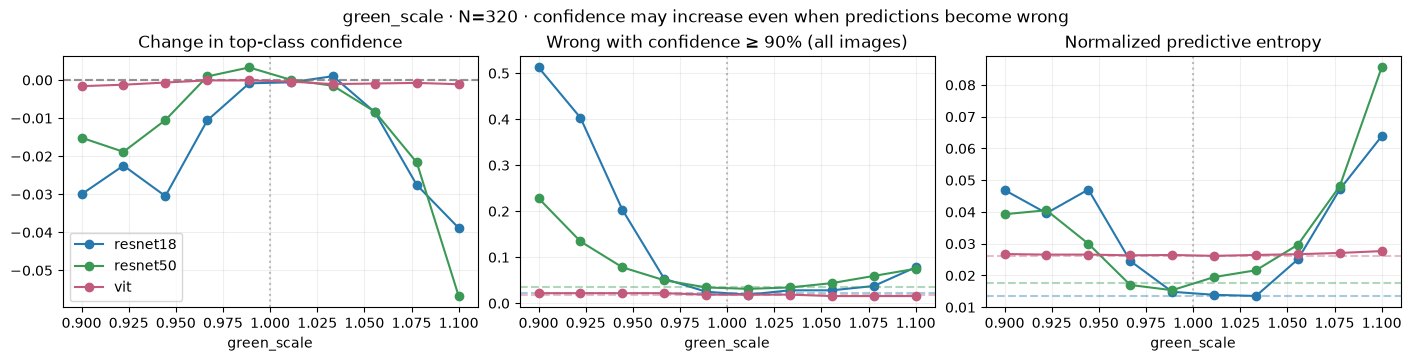

In [13]:
plot_confidence_change('green_scale', transformed['green_scale'])

Green-channel changes produce a 13.9% high-confidence-error fraction for ResNet18 while its mean confidence decreases by only 1.7 percentage points. In contrast, the ViT scores and decisions remain much closer to their original behavior. The ResNet18 result is a useful warning that a strong color response may not be accompanied by a strong uncertainty signal.

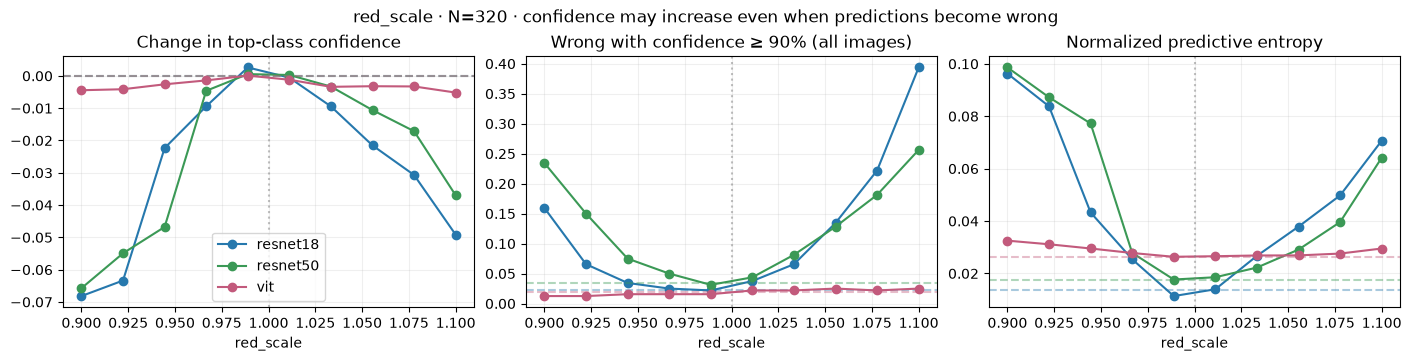

In [14]:
plot_confidence_change('red_scale', transformed['red_scale'])

Both CNNs retain high-confidence errors under red-channel scaling: 11.6% of pairs for ResNet18 and 12.3% for ResNet50. Entropy uses the full distribution and adds information beyond the maximum score, but it is still calculated from the same potentially overconfident model. Neither measure should be treated as an independent check of correctness.

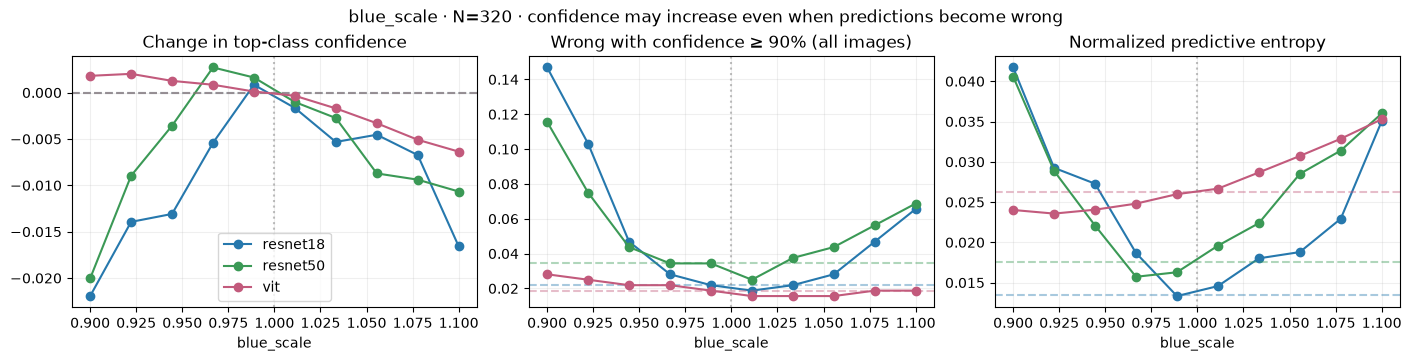

In [15]:
plot_confidence_change('blue_scale', transformed['blue_scale'])

Blue scaling has a smaller effect than red or green scaling, but both CNNs still produce high-confidence errors on approximately 5.3% of pairs. Small changes in average confidence therefore do not mean that every individual prediction is stable or correct. This view is useful mainly as a contrast to the stronger channel effects, not as evidence of complete blue-channel invariance.

## Extract every high-confidence error — original RGB image, test index, labels, all probabilities, confidence and entropy; threshold editable above

In [16]:
high_confidence_wrong = {}
for m, name in enumerate(model_names):
    ids = np.flatnonzero(~correct[m] & (confidence[m] >= threshold))
    ids = ids[np.argsort(-confidence[m, ids], kind='stable')]
    high_confidence_wrong[name] = ids
    path = Path(f'predictions/high_confidence_wrong_{name}.npz')
    np.savez_compressed(path, images=images[ids], sample_index=ids, true_label=labels[ids],
                        predicted_label=predicted[m, ids], probabilities=probabilities[m, ids],
                        confidence=confidence[m, ids], normalized_entropy=uncertainty[m, ids],
                        class_names=class_names, model=name, split='test', threshold=threshold,
                        logits=np.load(f'predictions/{name}_test.npz')['logits'][ids])
    print(f'{name}: {len(ids)} high-confidence errors → {path}')


resnet18: 70 high-confidence errors → predictions\high_confidence_wrong_resnet18.npz
resnet50: 79 high-confidence errors → predictions\high_confidence_wrong_resnet50.npz
vit: 52 high-confidence errors → predictions\high_confidence_wrong_vit.npz


## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


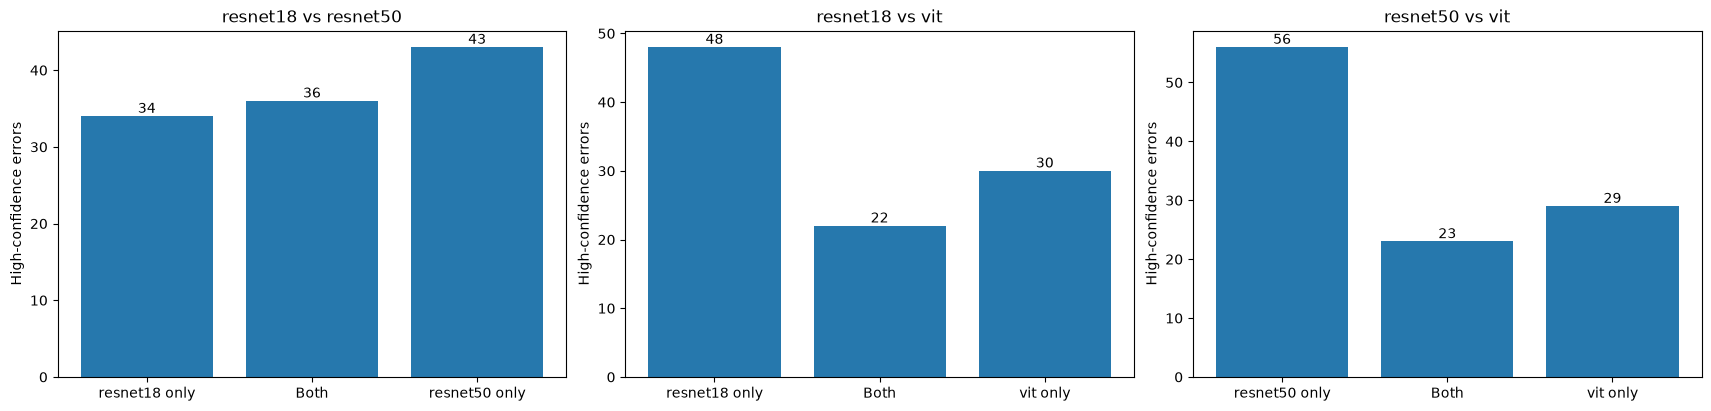

In [17]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


ResNet18 and ResNet50 share 36 high-confidence errors, compared with 22 and 23 for their respective pairs with ViT. Their Jaccard overlap is also higher, at 31.9% versus about 21–22%, so this is not just a comparison of raw error counts. The shared failures suggest that agreement can leave common blind spots, but the non-shared errors show that the models are not interchangeable.

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

resnet18: immature granulocytes → monocyte: 13/70 (18.6%)
resnet18: immature granulocytes → neutrophil: 11/70 (15.7%)
resnet18: neutrophil → immature granulocytes: 9/70 (12.9%)
resnet18: immature granulocytes → lymphocyte: 6/70 (8.6%)
resnet18: monocyte → immature granulocytes: 5/70 (7.1%)
resnet50: monocyte → immature granulocytes: 12/79 (15.2%)
resnet50: neutrophil → immature granulocytes: 11/79 (13.9%)
resnet50: immature granulocytes → monocyte: 10/79 (12.7%)
resnet50: immature granulocytes → neutrophil: 10/79 (12.7%)
resnet50: basophil → immature granulocytes: 5/79 (6.3%)
vit: monocyte → immature granulocytes: 9/52 (17.3%)
vit: immature granulocytes → monocyte: 8/52 (15.4%)
vit: neutrophil → immature granulocytes: 8/52 (15.4%)
vit: basophil → immature granulocytes: 7/52 (13.5%)
vit: immature granulocytes → neutrophil: 6/52 (11.5%)


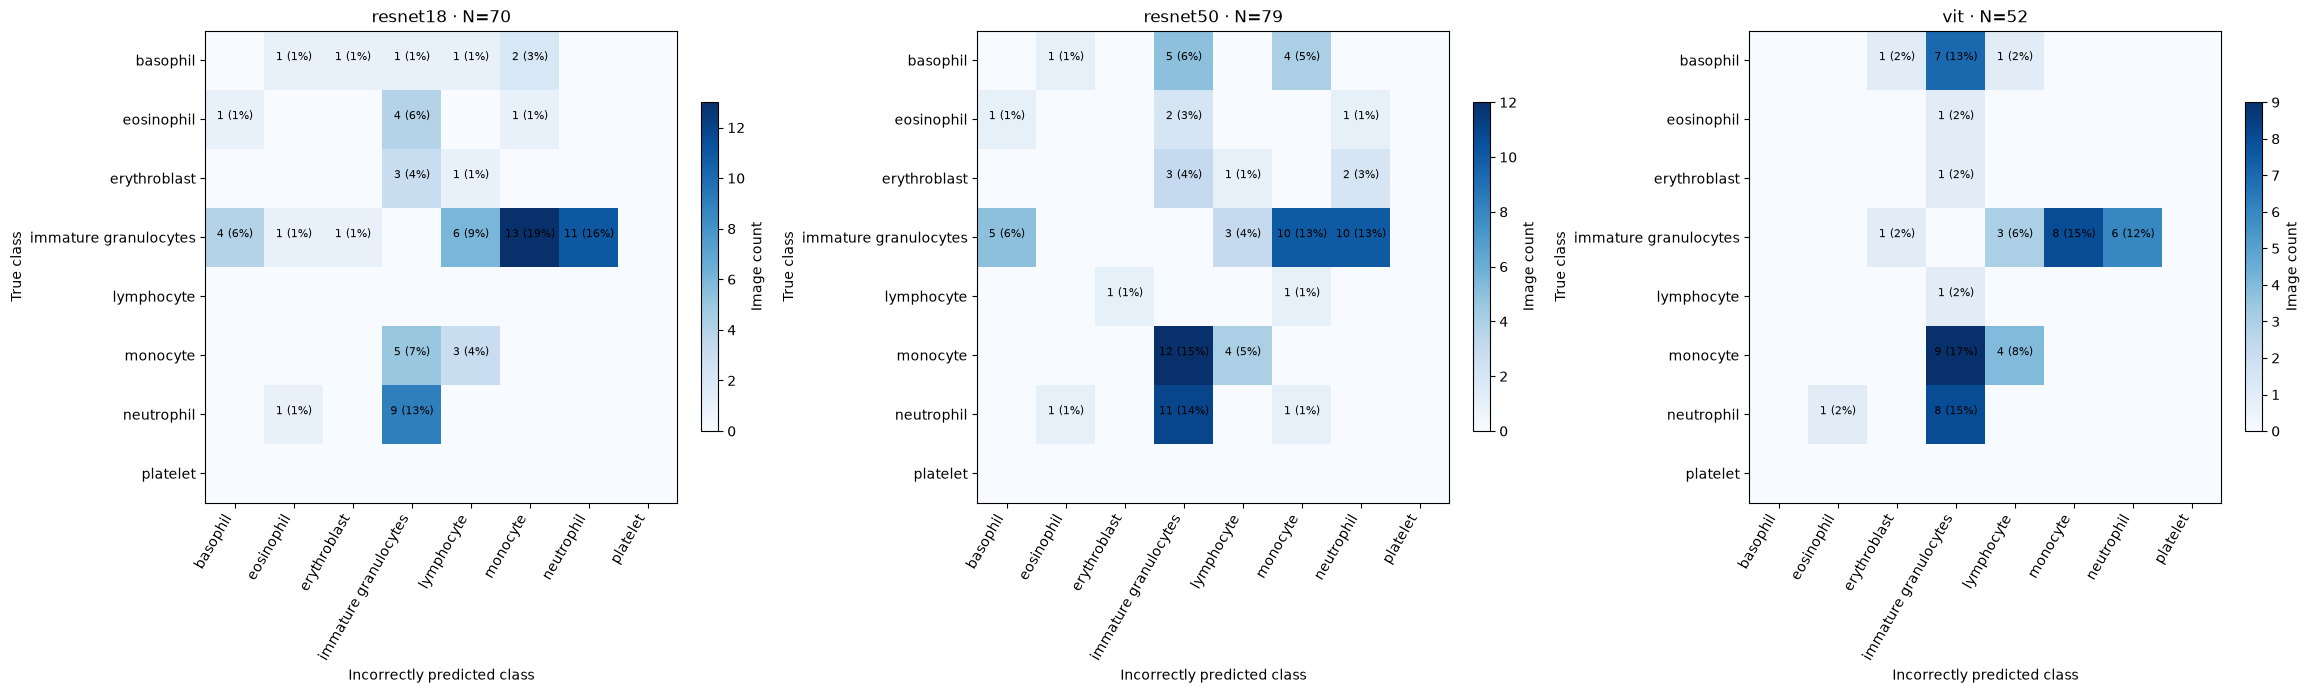

In [18]:
confusions, example_ids = [], []
fig, axes = plt.subplots(1, len(model_names), figsize=(23, 7), layout='constrained')
for m, (ax, ids) in enumerate(zip(axes, error_ids)):
    matrix = np.zeros((8, 8), dtype=int)
    np.add.at(matrix, (labels[ids], predicted[m, ids]), 1)
    confusions.append(matrix)
    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(matrix.max(), 1))
    ax.set(title=f'{model_names[m]} · N={len(ids)}', xlabel='Incorrectly predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c, d in zip(*np.nonzero(matrix)):
        ax.text(d, c, f'{matrix[c, d]} ({matrix[c, d] / len(ids):.0%})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.6, label='Image count')
    pairs = np.dstack(np.unravel_index(np.argsort(-matrix.ravel(), kind='stable'), matrix.shape))[0]
    pairs = [(c, d) for c, d in pairs if matrix[c, d] > 0]
    for c, d in pairs[:5]:
        print(f'{model_names[m]}: {class_names[c]} → {class_names[d]}: {matrix[c, d]}/{len(ids)} ({matrix[c, d] / len(ids):.1%})')
    example_ids.append(np.array([ids[np.flatnonzero((labels[ids] == c) & (predicted[m, ids] == d))[0]] for c, d in pairs[:3]], dtype=int))
plt.show()

Immature granulocytes occur on either side of 58 of 70 ResNet18 error pairs, 61 of 79 ResNet50 pairs and 45 of 52 ViT pairs. The errors are therefore structured rather than spread evenly over all class combinations, but no single confusion explains them all. These plots show counts, not per-class error risk; the later class-rate heatmap checks whether the pattern is simply due to class frequency.

## Simple RGB features — boundary gradient energy is only a proxy for edge content, not cell location or segmentation

In [19]:
rgb = images.astype(float) / 255
luminance = rgb @ np.array([0.299, 0.587, 0.114])
maximum, minimum = rgb.max(-1), rgb.min(-1)
saturation = np.divide(maximum - minimum, maximum, out=np.zeros_like(maximum), where=maximum > 0)
gy, gx = np.gradient(luminance, axis=(1, 2))
energy = np.hypot(gx, gy)
border = np.ones((28, 28), dtype=bool)
border[4:-4, 4:-4] = False
boundary_energy = energy[:, border].sum(-1) / np.maximum(energy.sum((1, 2)), 1e-12)
features = np.column_stack((luminance.mean((1, 2)), saturation.mean((1, 2)),
                            rgb.mean((1, 2)), luminance.std((1, 2)), boundary_energy))
feature_names = ['Mean brightness', 'Mean saturation', 'Mean red', 'Mean green', 'Mean blue',
                 'Luminance contrast (std)', 'Boundary gradient fraction']
control_weights, feature_effects = [], []
for m, ids in enumerate(error_ids):
    weights = np.zeros(len(labels))
    for c in range(8):
        mask = correct[m] & (labels == c)
        if mask.any() and len(ids):
            weights[mask] = (labels[ids] == c).mean() / mask.sum()
    control_weights.append(weights)
    if not len(ids):
        feature_effects.append(np.full(len(feature_names), np.nan))
        continue
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    effects = (features[ids].mean(0) - mean) / np.maximum(std, 1e-12)
    feature_effects.append(effects)

def plot_feature_comparison(m):
    ids = error_ids[m]
    weights, effects = control_weights[m], feature_effects[m]
    fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout='constrained')
    for j, ax in enumerate(axes.flat[:7]):
        edges = np.linspace(features[:, j].min(), features[:, j].max() + 1e-12, 16)
        ax.hist(features[:, j], bins=edges, weights=weights, histtype='step', linewidth=2, label='Correct, class-matched weights')
        ax.hist(features[ids, j], bins=edges, weights=np.full(len(ids), 1 / len(ids)),
                histtype='step', linewidth=2, label='High-confidence errors')
        ax.set(title=feature_names[j], ylabel='Fraction within group')
    axes[0, 0].legend(fontsize=7)
    axes[1, 3].barh(feature_names, effects)
    axes[1, 3].axvline(0, color='gray')
    axes[1, 3].set(title='Error minus correct mean', xlabel='Correct-control standard deviations')
    fig.suptitle(f'{model_names[m]} — correct controls weighted to the error group’s true-class proportions')
    plt.show()

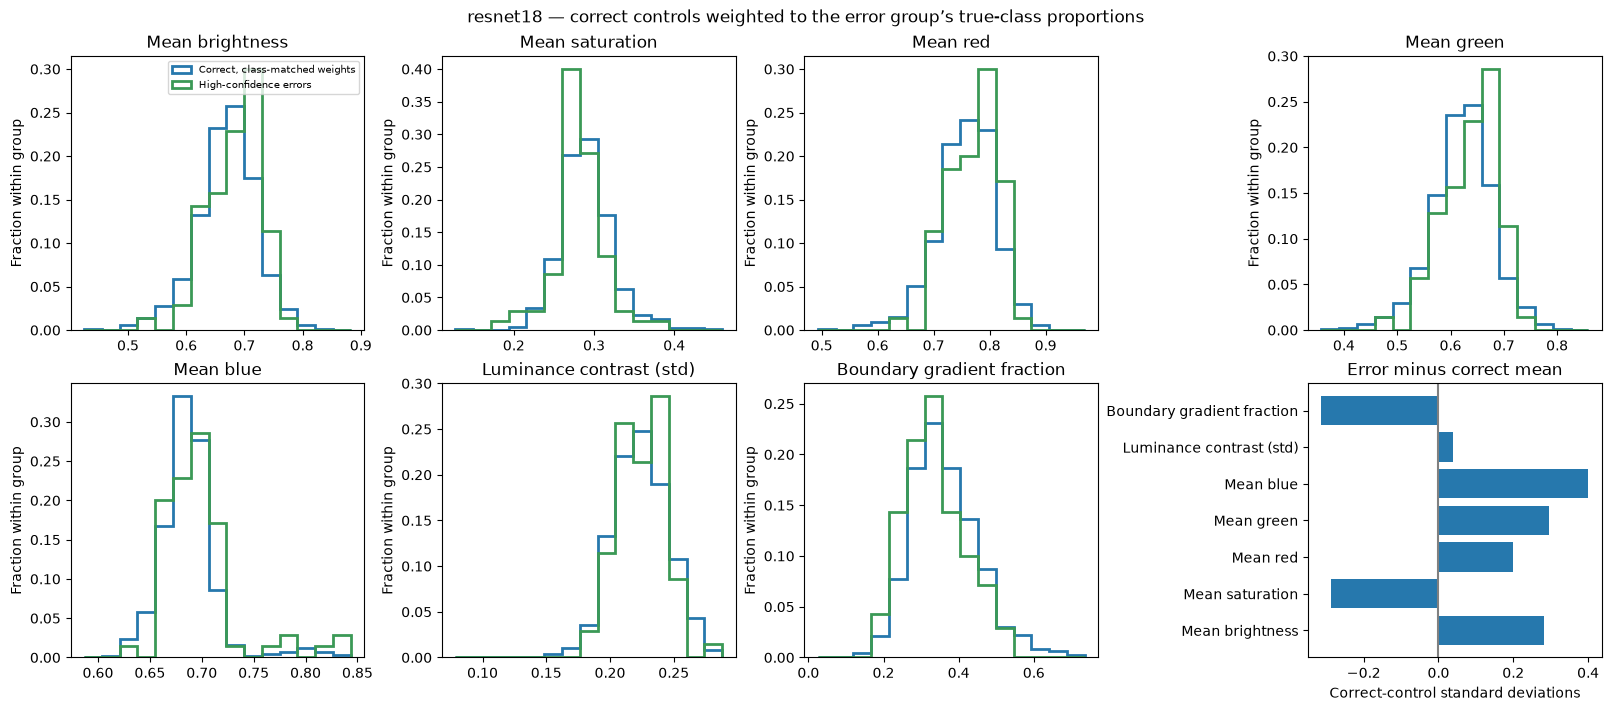

In [20]:
plot_feature_comparison(0)

ResNet18 high-confidence errors have somewhat higher blue values (+0.40 control SD) and lower saturation (−0.29 SD) than correctly classified, class-weighted controls. The overlapping distributions mean these properties cannot explain or detect every error. They suggest an appearance-related hypothesis worth testing, not a rule that brighter or less saturated cells must be misclassified.

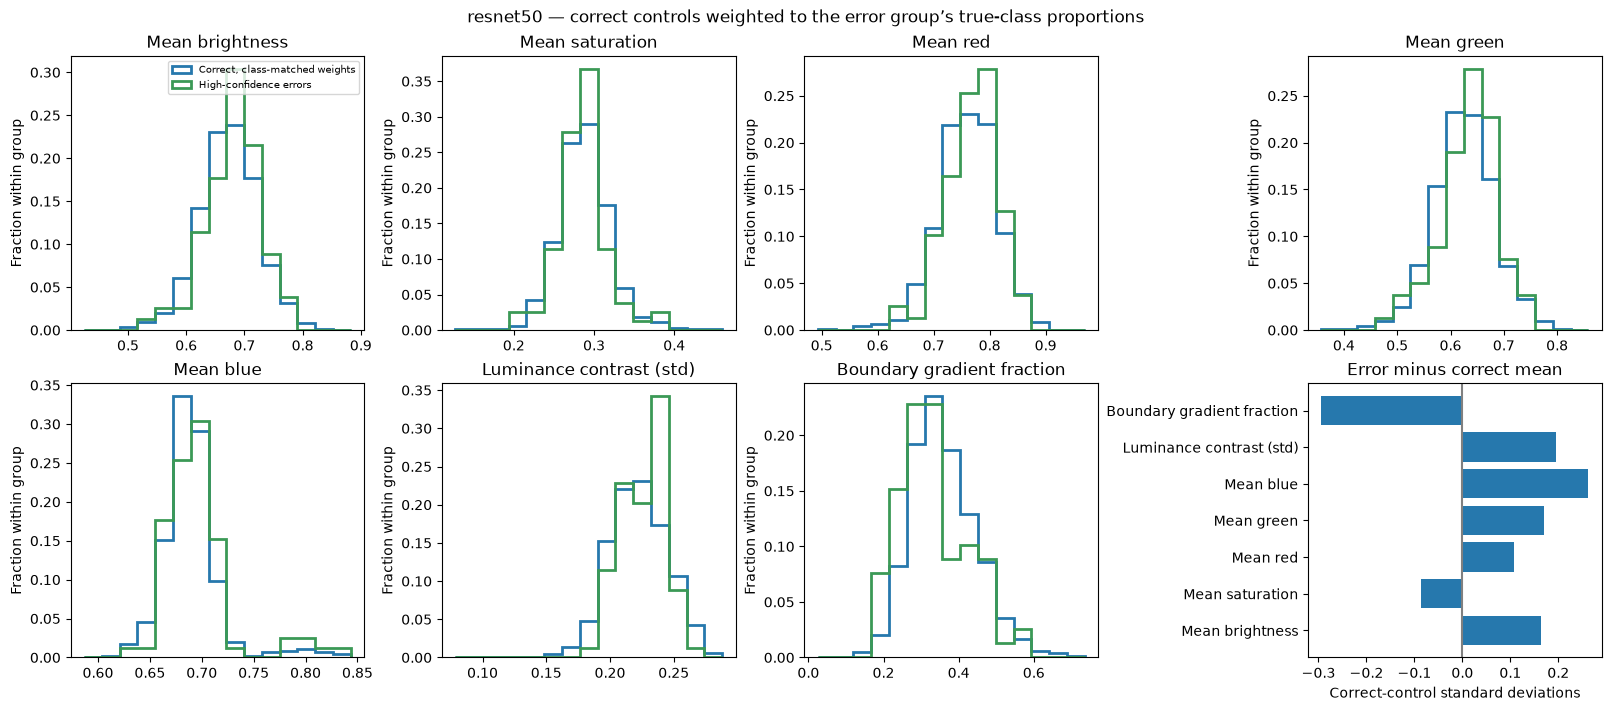

In [21]:
plot_feature_comparison(1)

ResNet50 errors show modest shifts, including higher blue values (+0.26 control SD) and lower boundary gradient fraction (−0.29 SD). There is no single feature that clearly separates the two groups. In particular, the boundary measure describes where image gradients occur, not whether an annotated cell lies near the border.

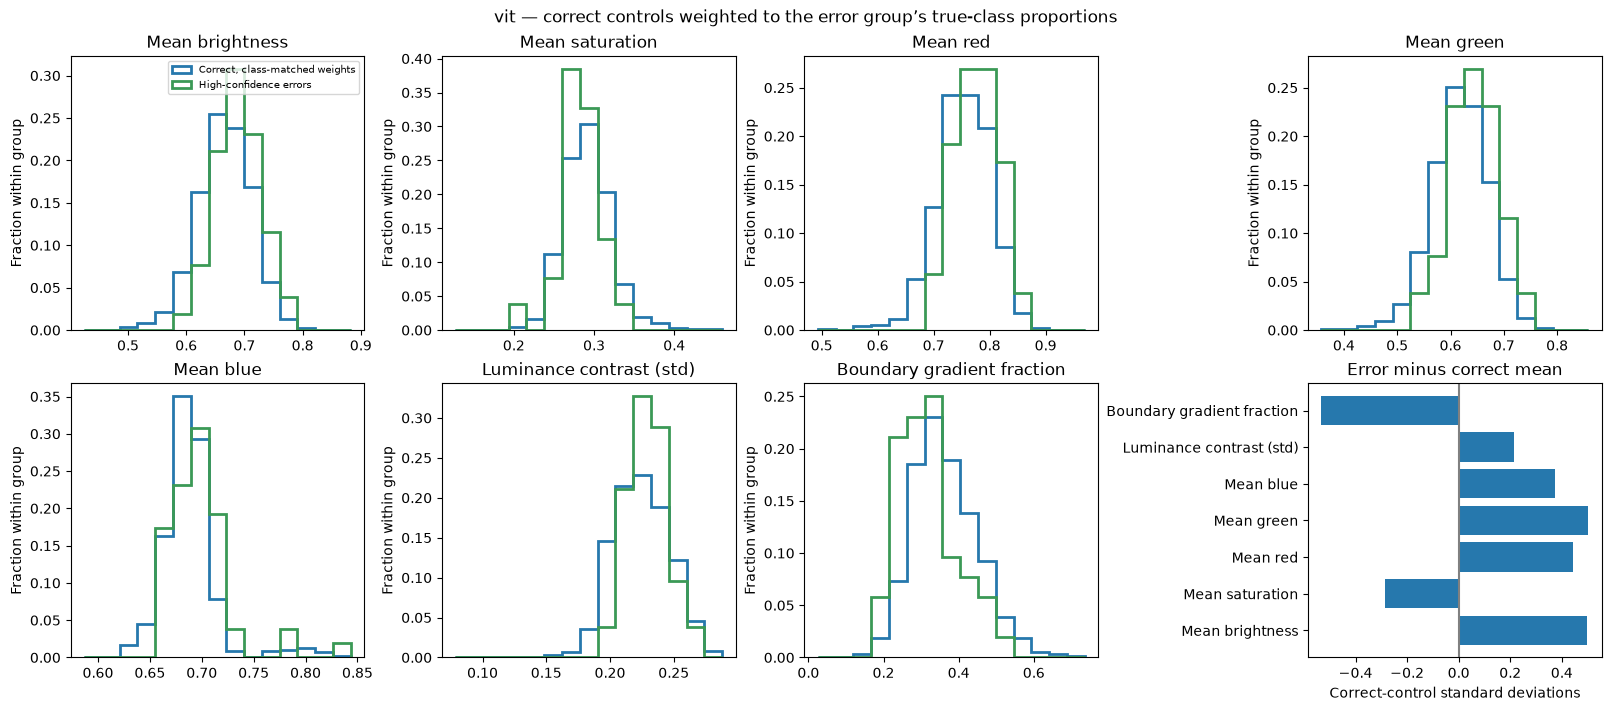

In [22]:
plot_feature_comparison(2)

ViT high-confidence errors are brighter (+0.50 control SD) and have less boundary gradient energy (−0.53 SD) than its class-weighted correct controls. These differences remain after matching the true-class proportions, but may still reflect several related appearance properties. They should guide controlled follow-up experiments rather than be interpreted as a discovered model mechanism.

## Similar correctly classified images — nearest raw-RGB RMSE match in the true and predicted classes; class sizes and image alignment affect similarity

In [23]:
flat = rgb.reshape(len(images), -1).astype(np.float32)
squared = np.square(flat).sum(-1)
neighbor_ids, neighbor_rmse = [], []
for m, ids in enumerate(error_ids):
    distances = np.maximum(squared[:, None] + squared[ids][None, :] - 2 * flat @ flat[ids].T, 0) / flat.shape[1]
    matches, rmses = [], []
    for target in [labels[ids], predicted[m, ids]]:
        allowed = correct[m, :, None] & (labels[:, None] == target[None, :])
        assert allowed.any(axis=0).all(), 'No correct comparison image in a requested class'
        nearest = np.where(allowed, distances, np.inf).argmin(axis=0)
        matches.append(nearest)
        rmses.append(np.sqrt(distances[nearest, np.arange(len(ids))]))
    neighbor_ids.append(np.stack(matches))
    neighbor_rmse.append(np.stack(rmses))

def plot_neighbors(m):
    ids = error_ids[m]
    matches, rmses = neighbor_ids[m], neighbor_rmse[m]
    if not len(example_ids[m]):
        return
    print(f'{model_names[m]}: predicted-class neighbor closer in {(rmses[1] < rmses[0]).mean():.1%} of high-confidence errors')
    fig, axes = plt.subplots(len(example_ids[m]), 3, figsize=(10, 3 * len(example_ids[m])), squeeze=False, layout='constrained')
    for row, i in enumerate(example_ids[m]):
        pos = np.flatnonzero(ids == i)[0]
        comparison = [i, matches[0][pos], matches[1][pos]]
        titles = ['High-confidence error', 'Correct true-class neighbor', 'Correct predicted-class neighbor']
        for col, (j, title) in enumerate(zip(comparison, titles)):
            ax = axes[row, col]
            ax.imshow(images[j])
            ax.set_title(f'{title} · #{j}', fontsize=10)
            ax.set_xlabel(f'True: {class_names[labels[j]]}; predicted: {class_names[predicted[m, j]]}; p={confidence[m, j]:.1%}', fontsize=7)
            if col:
                ax.set_ylabel(f'RGB RMSE: {rmses[col - 1][pos]:.3f}')
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle(f'{model_names[m]} — one example from each of the three largest error groups')
    plt.show()

resnet18: predicted-class neighbor closer in 62.9% of high-confidence errors


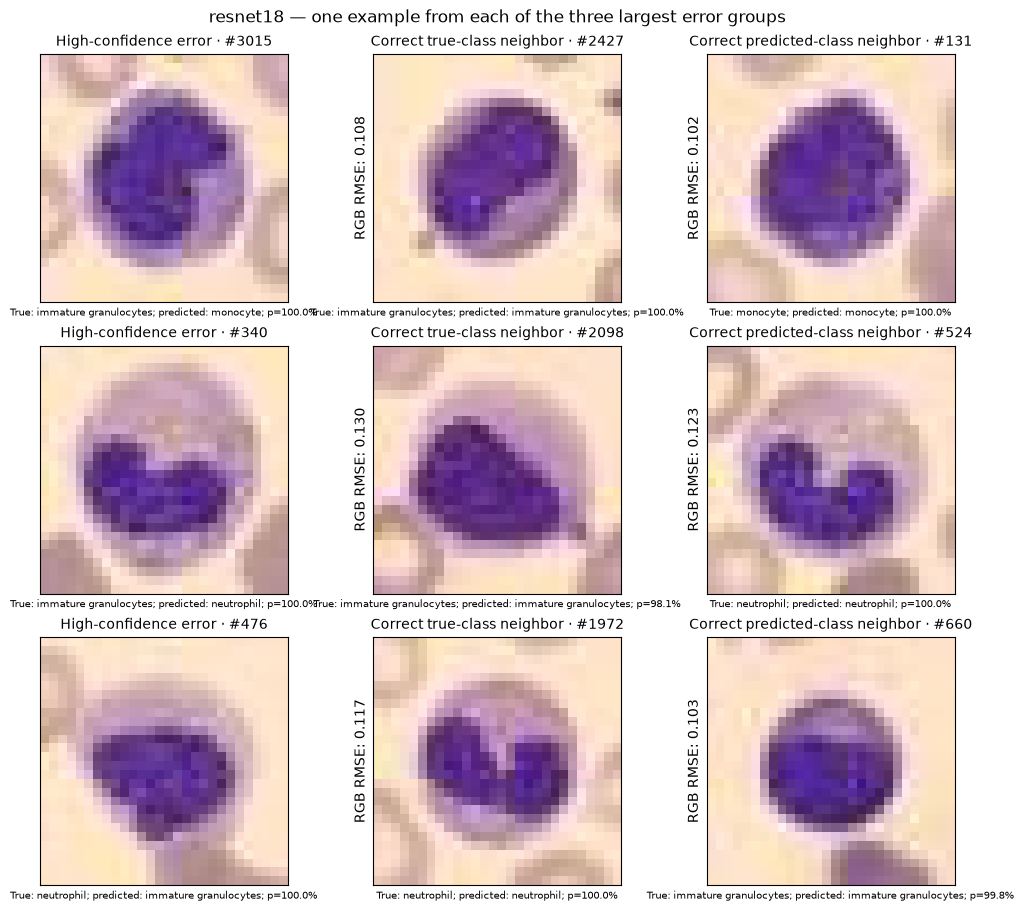

In [24]:
plot_neighbors(0)

For 62.9% of ResNet18 high-confidence errors, the nearest correct predicted-class image is closer in RGB distance than the nearest correct true-class image. Some errors therefore resemble examples of the class the model selected, at least under this simple image measure. However, RGB distance is sensitive to alignment and background, and unequal class sizes give different chances of finding a close neighbor.

resnet50: predicted-class neighbor closer in 59.5% of high-confidence errors


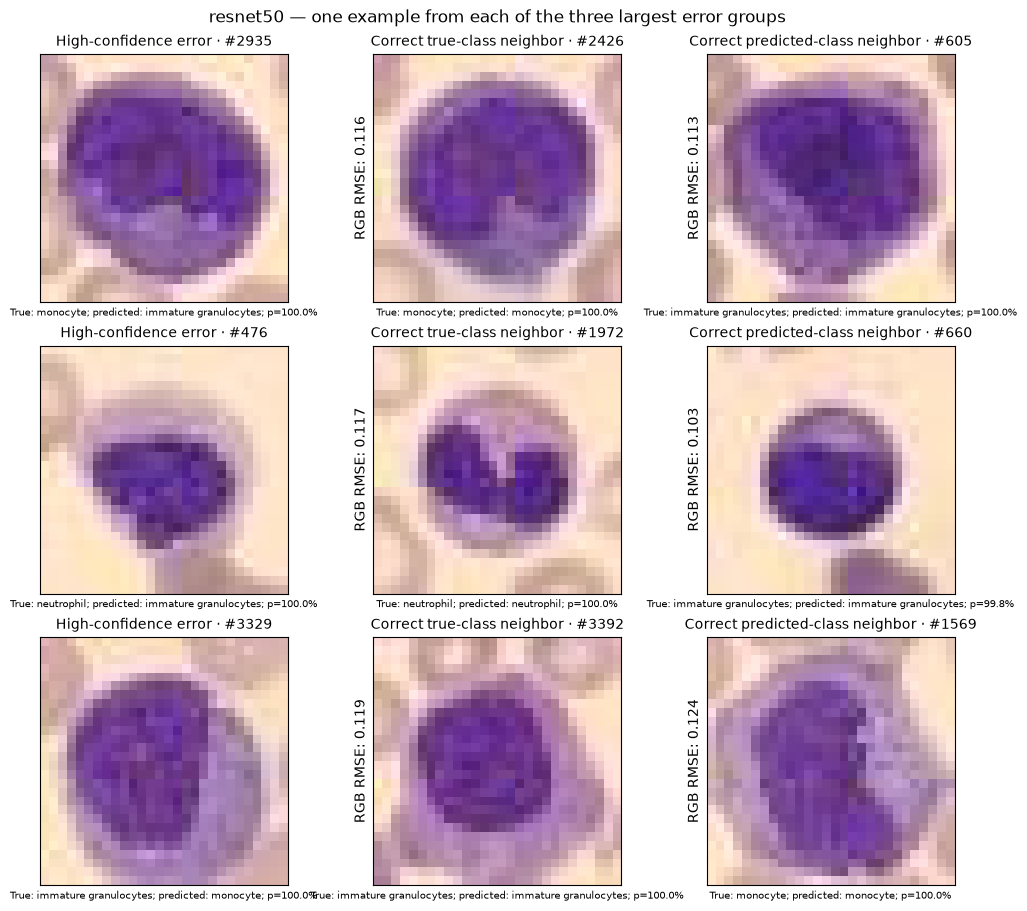

In [25]:
plot_neighbors(1)

For ResNet50, the predicted-class neighbor is closer in 59.5% of high-confidence errors. This supports inspecting visually similar class pairs rather than assuming every error is an unusual-looking image. The comparison remains descriptive because pixel similarity is not the same as diagnostic similarity.

vit: predicted-class neighbor closer in 61.5% of high-confidence errors


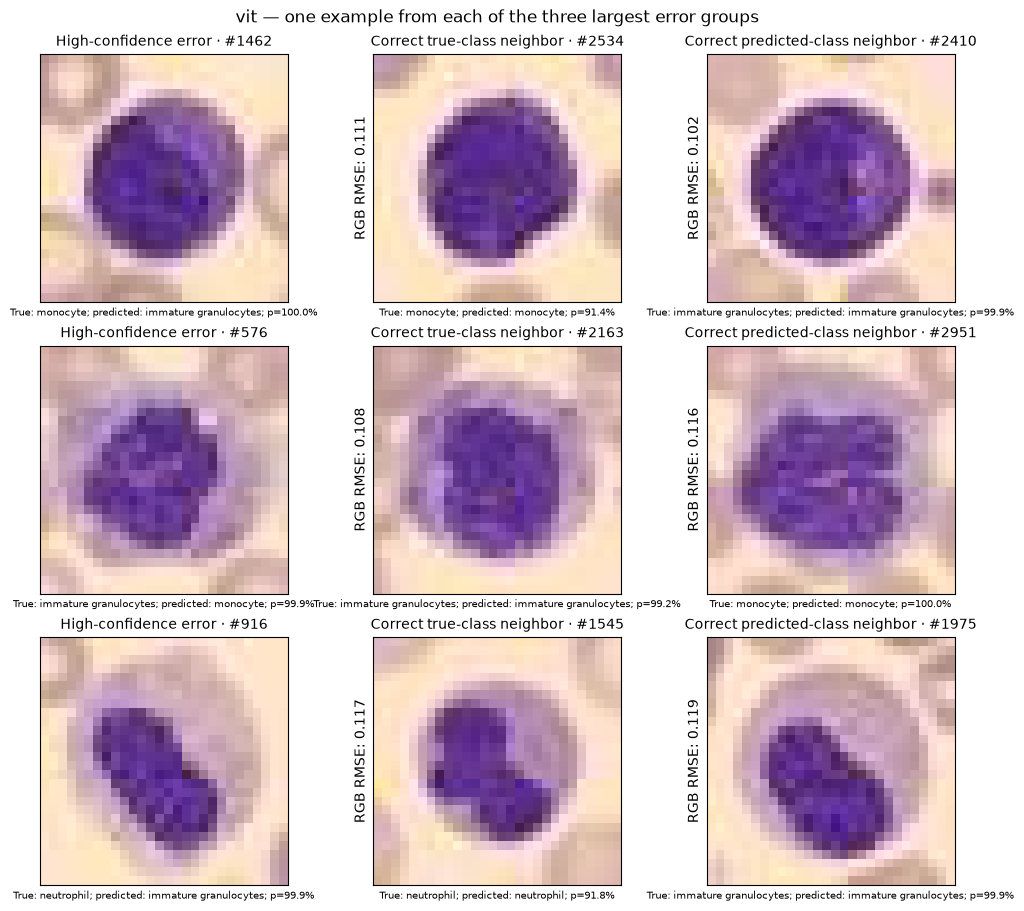

In [26]:
plot_neighbors(2)

For ViT, the predicted-class neighbor is closer in 61.5% of high-confidence errors. The examples can help identify candidate class ambiguities even though the distance does not use internal model features. They cannot establish that ViT made its decision for the same visual reason, so expert review is still needed.

## Load models for interventions — no training; saturation and occlusion act on original 28 × 28 RGB images

In [27]:
import torch
from PIL import Image, ImageEnhance
from transformers import ViTForImageClassification, ViTImageProcessor
from torchvision.models import resnet18
from models.resnet18.models import ResNet50

torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batch_size = 32
models = [resnet18(weights=None, num_classes=8), ResNet50(in_channels=3, num_classes=8)]
checkpoints = ['weights_bloodmnist/resnet18_224_1.pth', 'weights_bloodmnist/resnet50_28_1.pth', 'models/vit']
for model, path in zip(models, checkpoints):
    model.load_state_dict(torch.load(path, map_location='cpu', weights_only=True)['net'])
models.append(ViTForImageClassification.from_pretrained('models/vit', local_files_only=True))
models = [model.to(device).eval() for model in models]
processor = ViTImageProcessor.from_pretrained('models/vit', local_files_only=True)

@torch.inference_mode()
def predict(m, images):
    probabilities, scores = [], []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        if model_names[m] != 'vit':
            x = torch.from_numpy(batch.copy()).permute(0, 3, 1, 2).to(device).float()
            if model_names[m] == 'resnet18':
                x = torch.nn.functional.interpolate(x, size=(224, 224), mode='nearest')
            logits = models[m]((x / 255 - 0.5) / 0.5)
        else:
            inputs = processor(images=list(batch), return_tensors='pt').to(device)
            logits = models[m](**inputs).logits
        probabilities.append(logits.softmax(-1).cpu().numpy())
        scores.append(logits.cpu().numpy())
    return np.concatenate(probabilities), np.concatenate(scores)

def intervention_predict(m, batch_images):
    return predict(m, batch_images)[0]

for m, ids in enumerate(error_ids):
    if len(ids):
        np.testing.assert_allclose(intervention_predict(m, images[ids]), probabilities[m, ids], atol=1e-5, rtol=1e-4)


## Saturation intervention — errors versus their nearest correctly classified true-class controls; repeated control images are not independent samples

In [28]:
saturation_levels = np.linspace(0.5, 1.5, 11)
saturation_results, saturation_ids = [], []
for m, ids in enumerate(error_ids):
    selected = np.stack((ids, neighbor_ids[m][0]))
    saturation_ids.append(selected)
    if not len(ids):
        saturation_results.append(np.empty((2, 11, 0, 8)))
        continue
    inputs = images[selected.ravel()]
    values = []
    for level in saturation_levels:
        changed = np.stack([np.asarray(ImageEnhance.Color(Image.fromarray(image)).enhance(float(level))) for image in inputs])
        values.append(intervention_predict(m, changed).reshape(2, len(ids), 8))
    p = np.stack(values, axis=1)
    saturation_results.append(p)
    np.testing.assert_allclose(p[:, 5], probabilities[m, selected], atol=1e-5, rtol=1e-4)

def plot_saturation(m):
    ids, selected, p = error_ids[m], saturation_ids[m], saturation_results[m]
    wrong_probability = np.take_along_axis(p[0], predicted[m, ids][None, :, None], axis=-1)[..., 0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
    axes[0].plot(saturation_levels, wrong_probability.mean(-1), 'o-')
    axes[0].set(title='Errors: p(original incorrect class)', ylabel='Mean probability')
    for role, title in enumerate(['High-confidence errors', 'Matched correct controls']):
        accuracy = (p[role].argmax(-1) == labels[selected[role]]).mean(-1)
        axes[1].plot(saturation_levels, accuracy, 'o-', label=title)
        axes[2].plot(saturation_levels, p[role].max(-1).mean(-1), 'o-', label=title)
    axes[1].set(title='Accuracy / error correction rate', ylim=(-0.03, 1.03))
    axes[2].set(title='Mean top-class confidence')
    for ax in axes:
        ax.axvline(1, color='gray', ls='--')
        ax.set_xlabel('Saturation factor')
        ax.grid(alpha=0.2)
    axes[1].legend(fontsize=8)
    fig.suptitle(f'{model_names[m]} · {len(ids)} errors, {len(np.unique(selected[1]))} unique controls · no label-preservation guarantee')
    plt.show()

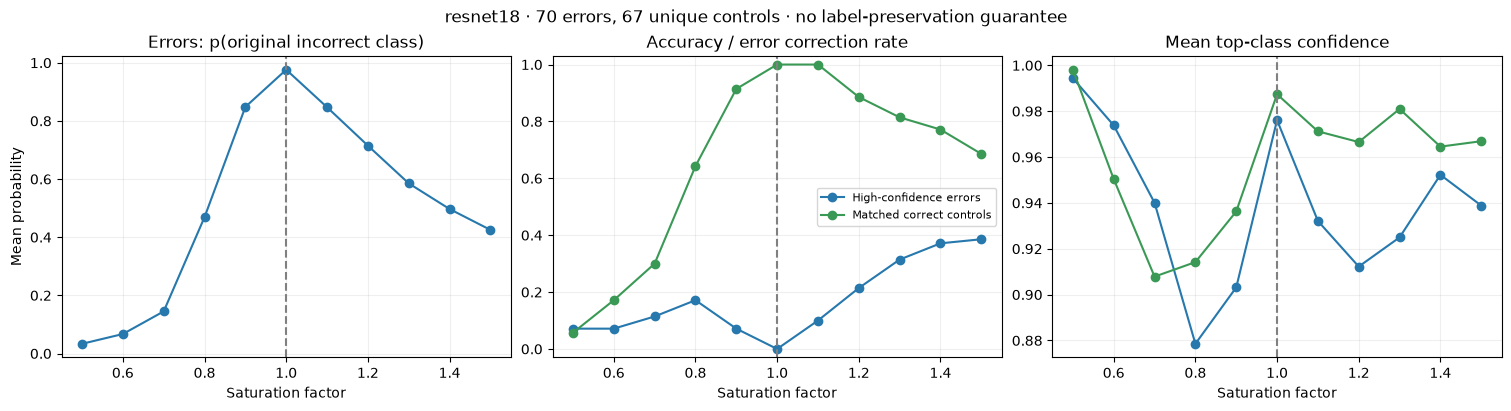

In [29]:
plot_saturation(0)

At saturation ×1.5, ResNet18 corrects 27 of its 70 original high-confidence errors but makes 22 matched control pairs incorrect. The intervention therefore changes decisions in both helpful and harmful directions. Selecting this factor after seeing these outcomes would not demonstrate a reliable improvement, especially because some control images are reused.

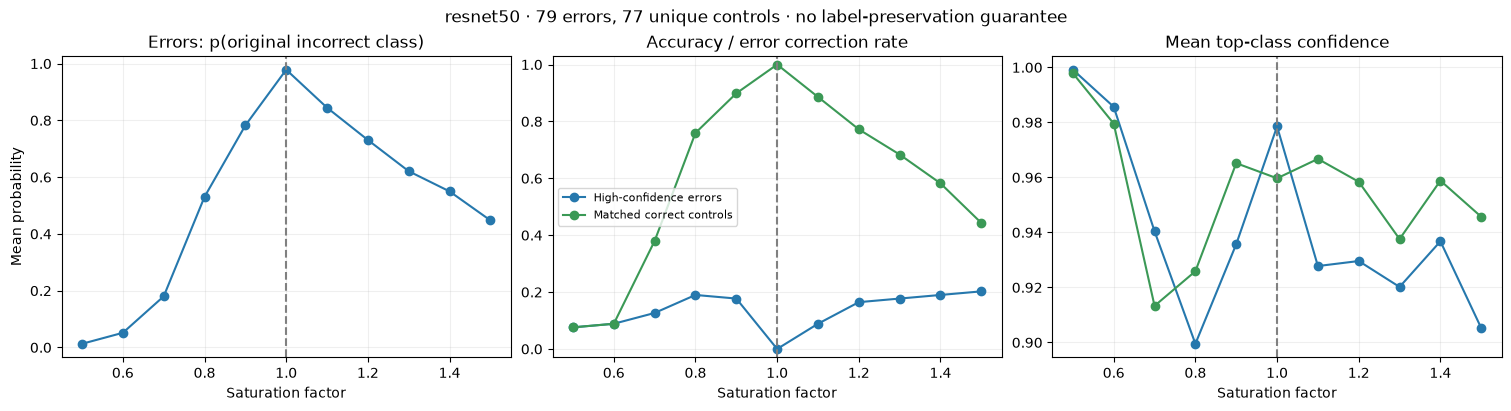

In [30]:
plot_saturation(1)

At saturation ×1.5, ResNet50 corrects 16 of 79 errors but makes 44 matched control pairs incorrect. A common color adjustment is therefore not a convincing fix for this error group. The more useful hypothesis is that individual predictions depend on appearance in different ways, which needs testing on new images rather than tuning to these errors.

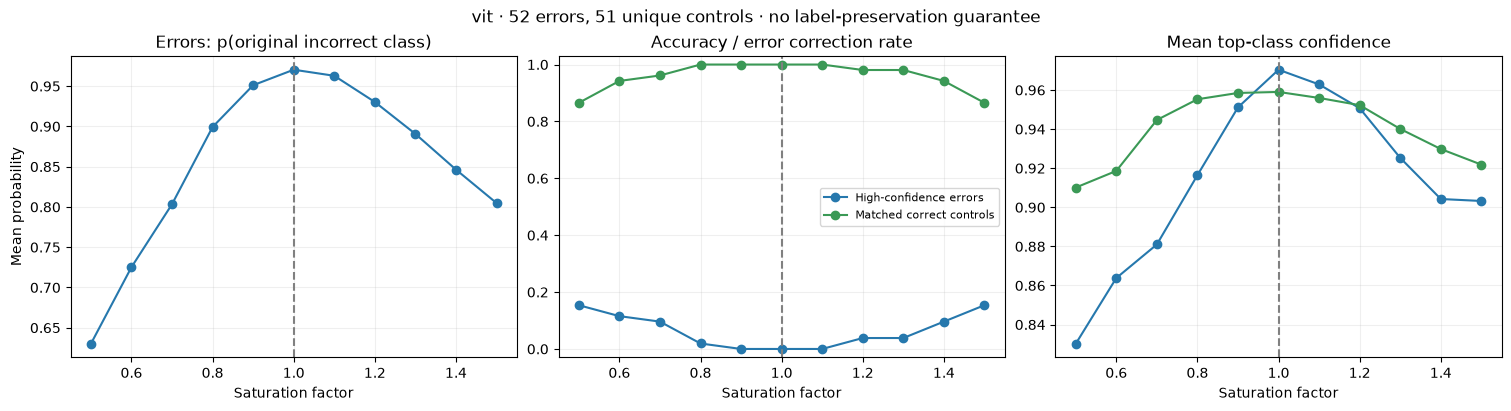

In [31]:
plot_saturation(2)

Reducing saturation to ×0.5 corrects 8 of 52 ViT errors but also damages 7 matched control pairs. Some appearance-related errors can change, but there is no clear general correction from this setting alone. A useful next step would test a predefined adjustment on unseen images and report both recovered errors and newly introduced errors.

## Occlusion — compute all 4 × 4 gray-patch interventions; show class aggregates rather than repeating selected image examples

In [32]:
patch_size = 4
positions = np.array([(y, x) for y in range(0, 28, patch_size) for x in range(0, 28, patch_size)])
occlusion_results, occlusion_drop = [], []
for m, ids in enumerate(error_ids):
    if not len(ids):
        occlusion_results.append(np.empty((49, 0, 8)))
        occlusion_drop.append(np.empty((0, 7, 7)))
        continue
    changed = np.repeat(images[ids][None], len(positions), axis=0)
    for j, (y, x) in enumerate(positions):
        changed[j, :, y:y + patch_size, x:x + patch_size] = 128
    p = intervention_predict(m, changed.reshape(-1, 28, 28, 3)).reshape(len(positions), len(ids), 8)
    occlusion_results.append(p)
    target = np.take_along_axis(p, predicted[m, ids][None, :, None], axis=-1)[..., 0]
    maps = (confidence[m, ids][None] - target).T.reshape(len(ids), 7, 7)
    occlusion_drop.append(maps)

## Occlusion aggregated by true class and model — all high-confidence errors; mean signed drop, absolute effect and correction fraction; N = images, not patches; fixed image coordinates are not aligned cell structures

In [33]:
occlusion_counts = np.zeros((len(model_names), 8), dtype=int)
occlusion_class_metrics = {name: np.full((len(model_names), 8, 7, 7), np.nan) for name in
                           ['Mean wrong-class probability drop', 'Mean absolute probability change', 'Fraction corrected']}
for m, ids in enumerate(error_ids):
    patch_predictions = occlusion_results[m].argmax(-1).T.reshape(len(ids), 7, 7)
    corrected = patch_predictions == labels[ids, None, None]
    for c in range(8):
        mask = labels[ids] == c
        occlusion_counts[m, c] = mask.sum()
        if mask.any():
            occlusion_class_metrics['Mean wrong-class probability drop'][m, c] = occlusion_drop[m][mask].mean(0)
            occlusion_class_metrics['Mean absolute probability change'][m, c] = np.abs(occlusion_drop[m][mask]).mean(0)
            occlusion_class_metrics['Fraction corrected'][m, c] = corrected[mask].mean(0)
            print(f'{model_names[m]} · {class_names[c]} · N={mask.sum()} · mean absolute effect={np.abs(occlusion_drop[m][mask]).mean():.3f} · correction fraction across patches={corrected[mask].mean():.1%}')

def plot_occlusion_summary(title):
    maps = occlusion_class_metrics[title]
    signed = title == 'Mean wrong-class probability drop'
    limit = 1 if title == 'Fraction corrected' else max(np.nanmax(np.abs(maps)), 0.01)
    fig, axes = plt.subplots(len(model_names), 8, figsize=(23, 3.5 * len(model_names)), layout='constrained')
    for m in range(len(model_names)):
        for c, ax in enumerate(axes[m]):
            if occlusion_counts[m, c]:
                im = ax.imshow(maps[m, c], cmap='RdBu_r' if signed else 'viridis',
                               vmin=-limit if signed else 0, vmax=limit)
            else:
                ax.set_facecolor('#eeeeee')
                ax.text(0.5, 0.5, 'No images', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{class_names[c]} (N={occlusion_counts[m, c]})', fontsize=8, wrap=True)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[m, 0].set_ylabel(model_names[m])
    fig.colorbar(im, ax=axes, shrink=0.65, label=title)
    fig.suptitle(f'{title} — each square covers 4 × 4 pixels; small classes are descriptive, not reliable comparisons')
    plt.show()

resnet18 · basophil · N=6 · mean absolute effect=0.136 · correction fraction across patches=1.7%
resnet18 · eosinophil · N=6 · mean absolute effect=0.092 · correction fraction across patches=6.8%
resnet18 · erythroblast · N=4 · mean absolute effect=0.075 · correction fraction across patches=5.6%
resnet18 · immature granulocytes · N=36 · mean absolute effect=0.123 · correction fraction across patches=9.0%
resnet18 · monocyte · N=8 · mean absolute effect=0.061 · correction fraction across patches=4.1%
resnet18 · neutrophil · N=10 · mean absolute effect=0.072 · correction fraction across patches=6.1%
resnet50 · basophil · N=10 · mean absolute effect=0.075 · correction fraction across patches=0.6%
resnet50 · eosinophil · N=4 · mean absolute effect=0.103 · correction fraction across patches=5.1%
resnet50 · erythroblast · N=6 · mean absolute effect=0.136 · correction fraction across patches=12.6%
resnet50 · immature granulocytes · N=28 · mean absolute effect=0.147 · correction fraction acros

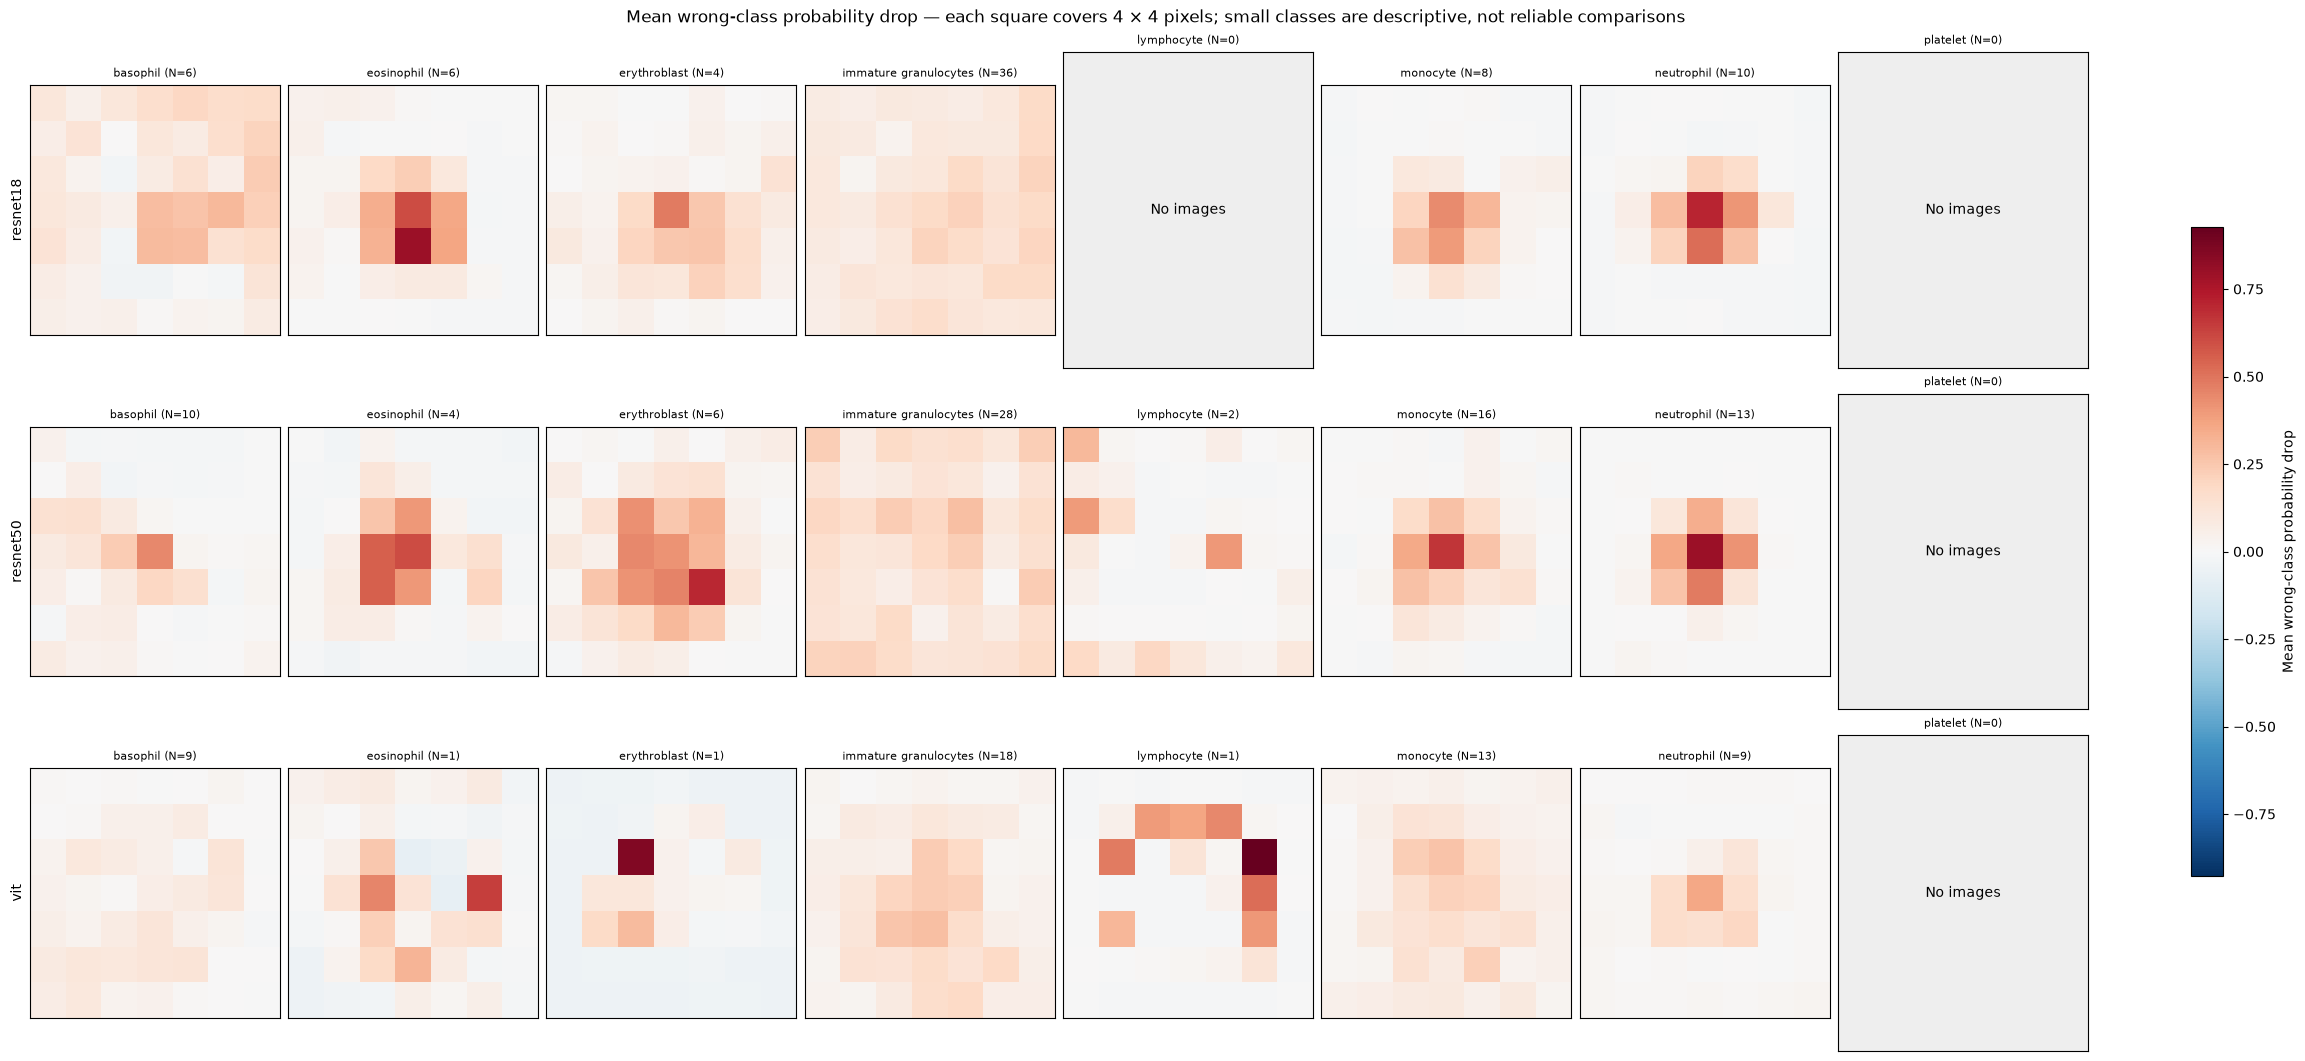

In [34]:
plot_occlusion_summary('Mean wrong-class probability drop')

Occluding central patches reduces the original wrong-class probability more than occluding other patches: mean drops are 0.20 versus 0.07 for ResNet18, 0.24 versus 0.06 for ResNet50 and 0.16 versus 0.05 for ViT. This suggests that central image content contributes to these wrong decisions, but does not identify a nucleus, cell boundary or causal biological feature. The class maps also have very different sample counts, so a class with one image should not be compared as if its average were well established.

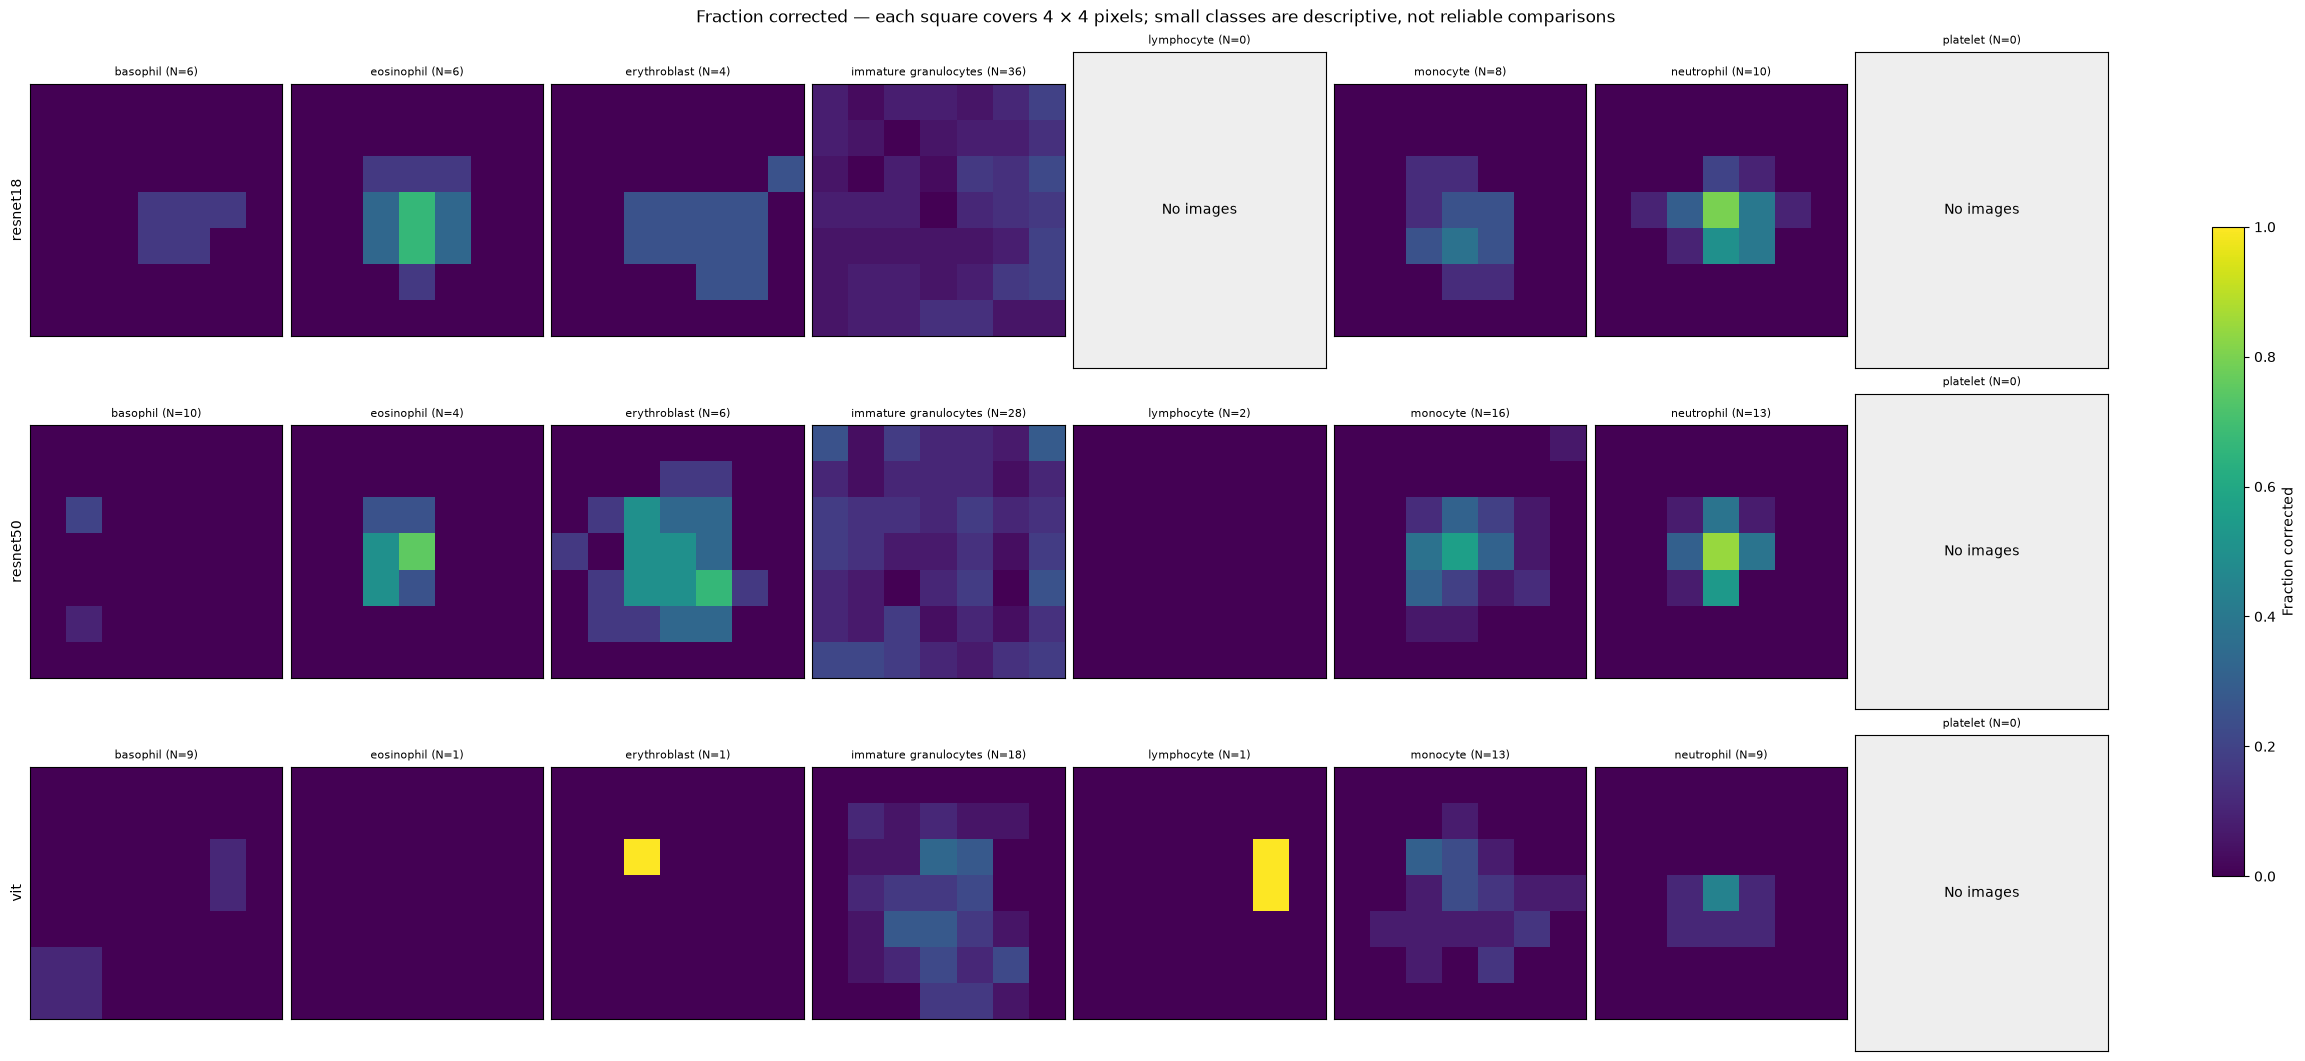

In [35]:
plot_occlusion_summary('Fraction corrected')

A large probability drop does not mean the model recovered the true class: only about 7.0%, 7.7% and 4.4% of patch interventions correct the original ResNet18, ResNet50 and ViT errors. Occlusion can weaken one wrong class while leaving another wrong class on top. This is why the correction map adds information beyond the probability-drop map, while a separate absolute-effect heatmap is omitted because it largely repeats the spatial sensitivity pattern here.

## Save all high-confidence-error analysis data — all examples and all intervention probabilities, not just the displayed selections

In [36]:
analysis = dict(shared_indices=shared, union_indices=union, threshold=threshold, split='test',
                model_names=model_names, class_names=class_names, features=features, feature_names=feature_names,
                checkpoints=checkpoints, model_input_resolutions=[224, 28, 224],
                pair_overlap=pair_overlap, pair_jaccard=pair_jaccard,
                feature_sample_index=np.arange(len(labels)), true_labels=labels, baseline_probabilities=probabilities,
                control_weights=np.stack(control_weights), feature_effects=np.stack(feature_effects),
                saturation_levels=saturation_levels, occlusion_positions=positions, patch_size=patch_size,
                occlusion_fill_rgb=[128, 128, 128], neighbor_roles=['true_class', 'predicted_class'],
                saturation_roles=['high_confidence_errors', 'matched_correct_controls'],
                occlusion_class_counts=occlusion_counts, occlusion_grouping='true_class',
                **{f'occlusion_class_{name}': maps for name, maps in occlusion_class_metrics.items()})
for m, name in enumerate(model_names):
    for key, value in dict(error_ids=error_ids[m], confusion=confusions[m], selected_examples=example_ids[m],
                           neighbor_ids=neighbor_ids[m], neighbor_rmse=neighbor_rmse[m],
                           saturation_ids=saturation_ids[m], saturation_probabilities=saturation_results[m],
                           occlusion_probabilities=occlusion_results[m], occlusion_drop=occlusion_drop[m]).items():
        analysis[f'{name}_{key}'] = value
    if len(error_ids[m]):
        j = np.abs(feature_effects[m]).argmax()
        corrections = (saturation_results[m][0].argmax(-1) == labels[error_ids[m]]).sum(-1)
        print(f'{name}: largest descriptive feature shift: {feature_names[j]} ({feature_effects[m][j]:+.2f} control SD)')
        control_errors = (saturation_results[m][1].argmax(-1) != labels[saturation_ids[m][1]]).sum(-1)
        print('Saturation factor / corrected errors / newly wrong matched control pairs:', list(zip(saturation_levels.round(2).tolist(), corrections.tolist(), control_errors.tolist())))
        involved = ((labels[error_ids[m]] == 3) | (predicted[m, error_ids[m]] == 3)).sum()
        print(f'{name}: immature granulocytes occur on either side of {involved}/{len(error_ids[m])} error pairs')
        print(f'{name}: mean largest wrong-class probability drop per image under occlusion: {occlusion_drop[m].max((1, 2)).mean():.3f}')
path = Path('predictions/high_confidence_error_analysis.npz')
np.savez_compressed(path, **analysis)
print(path)
print('Hypotheses to investigate: appearance/staining sensitivity in a subset of errors; visual ambiguity around immature-granulocyte confusions. Saturation can also damage correct controls, so correction counts alone are not evidence of improvement.')
print('Exploratory only: correlated color features, class composition, pixel alignment, unequal neighbor-pool sizes and artificial interventions prevent causal or biological conclusions. Validate hypotheses on new images, not these selected errors.')

## A · Shared and exclusive errors — all 39 shared errors; mark cases with ≥90% confidence in every model; class IDs listed below

Shared errors: 39 with ≥90% confidence in all models: 18
Classes: {0: np.str_('basophil'), 1: np.str_('eosinophil'), 2: np.str_('erythroblast'), 3: np.str_('immature granulocytes'), 4: np.str_('lymphocyte'), 5: np.str_('monocyte'), 6: np.str_('neutrophil'), 7: np.str_('platelet')}


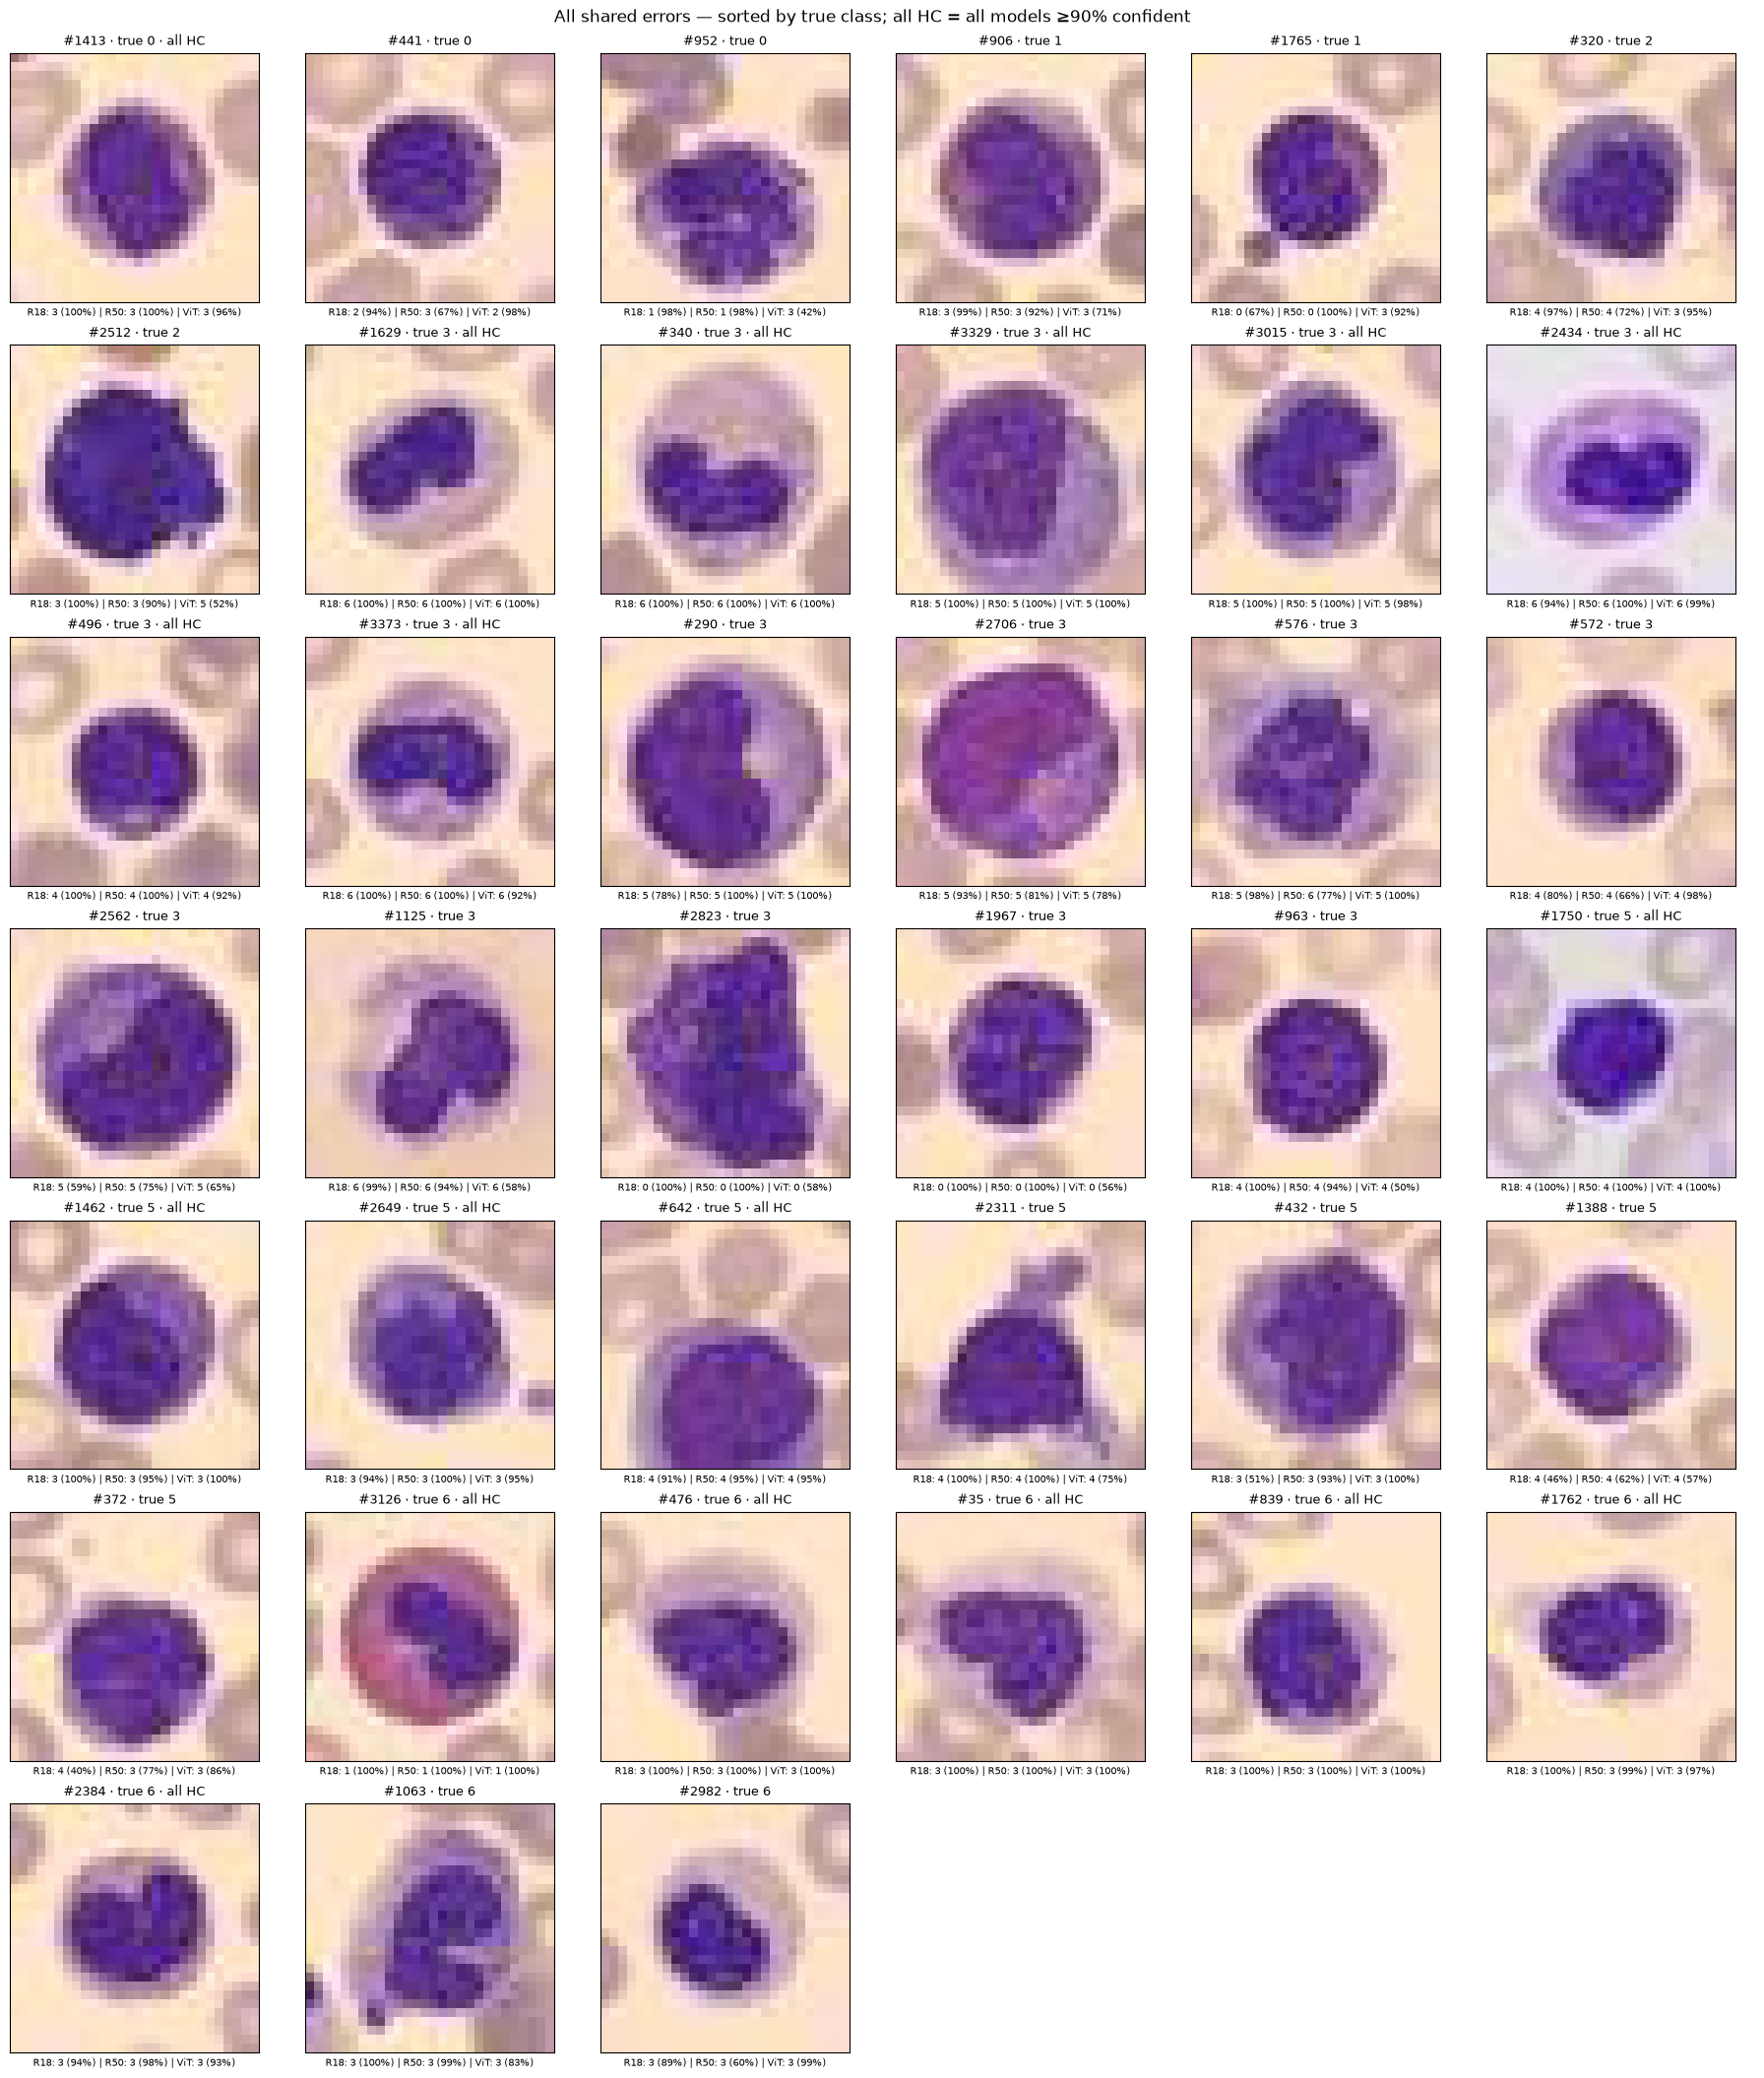

In [37]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Shared errors:', len(common_wrong), 'with ≥90% confidence in all models:', len(common_hc))
print('Classes:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · true {labels[i]}' + (' · all HC' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'All shared errors — sorted by true class; all HC = all models ≥90% confident')

All three models misclassify these 39 images; the 18 marked “all HC” receive at least 90% confidence from every model. All three choose the same wrong class on those 18, and nine confuse immature granulocytes with neutrophils or vice versa. The repeated class patterns make these useful cases for independent image and label review, rather than assuming model agreement confirms the label.

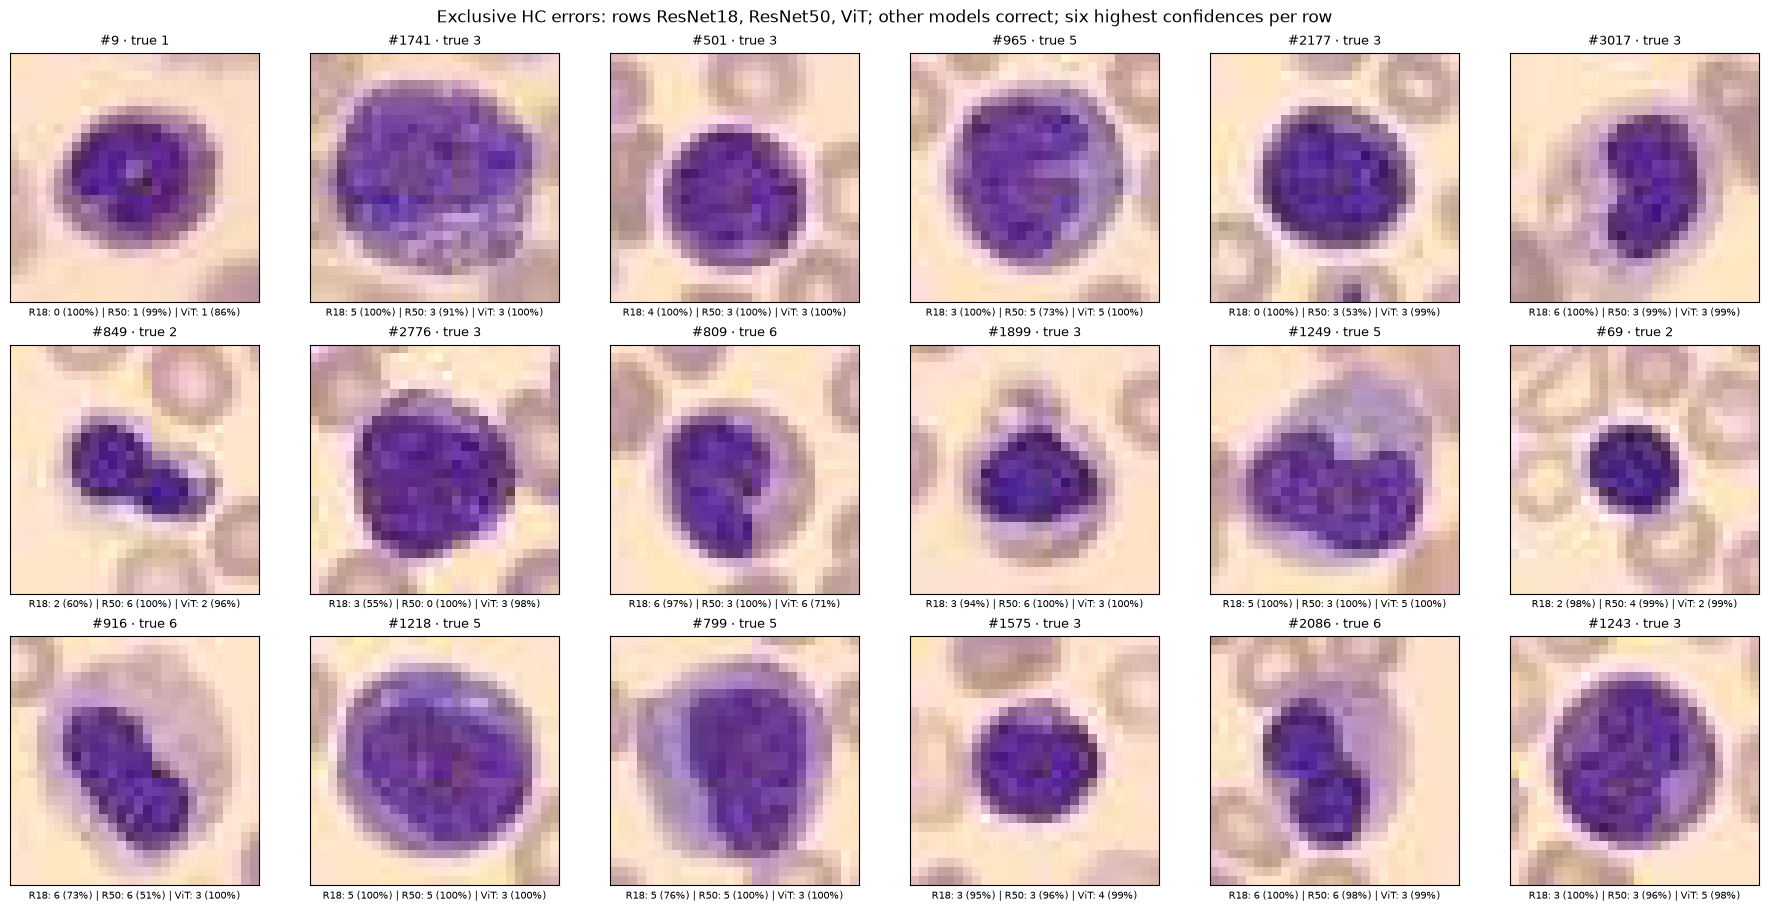

In [38]:
exclusive_examples = np.concatenate([ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
                                     for m, ids in enumerate(exclusive_hc)])
gallery(exclusive_examples, 'Exclusive HC errors: rows ResNet18, ResNet50, ViT; other models correct; six highest confidences per row')

These rows show errors made only by ResNet18, only by ResNet50 and only by ViT, while the other two models are correct. Their existence suggests some complementary behavior, but does not show that voting would solve the shared failures above. The examples were selected by confidence, not to represent the usual appearance of each error group.

## A · Matched images — errors beside similar same-class controls classified correctly with ≥90% confidence by every model

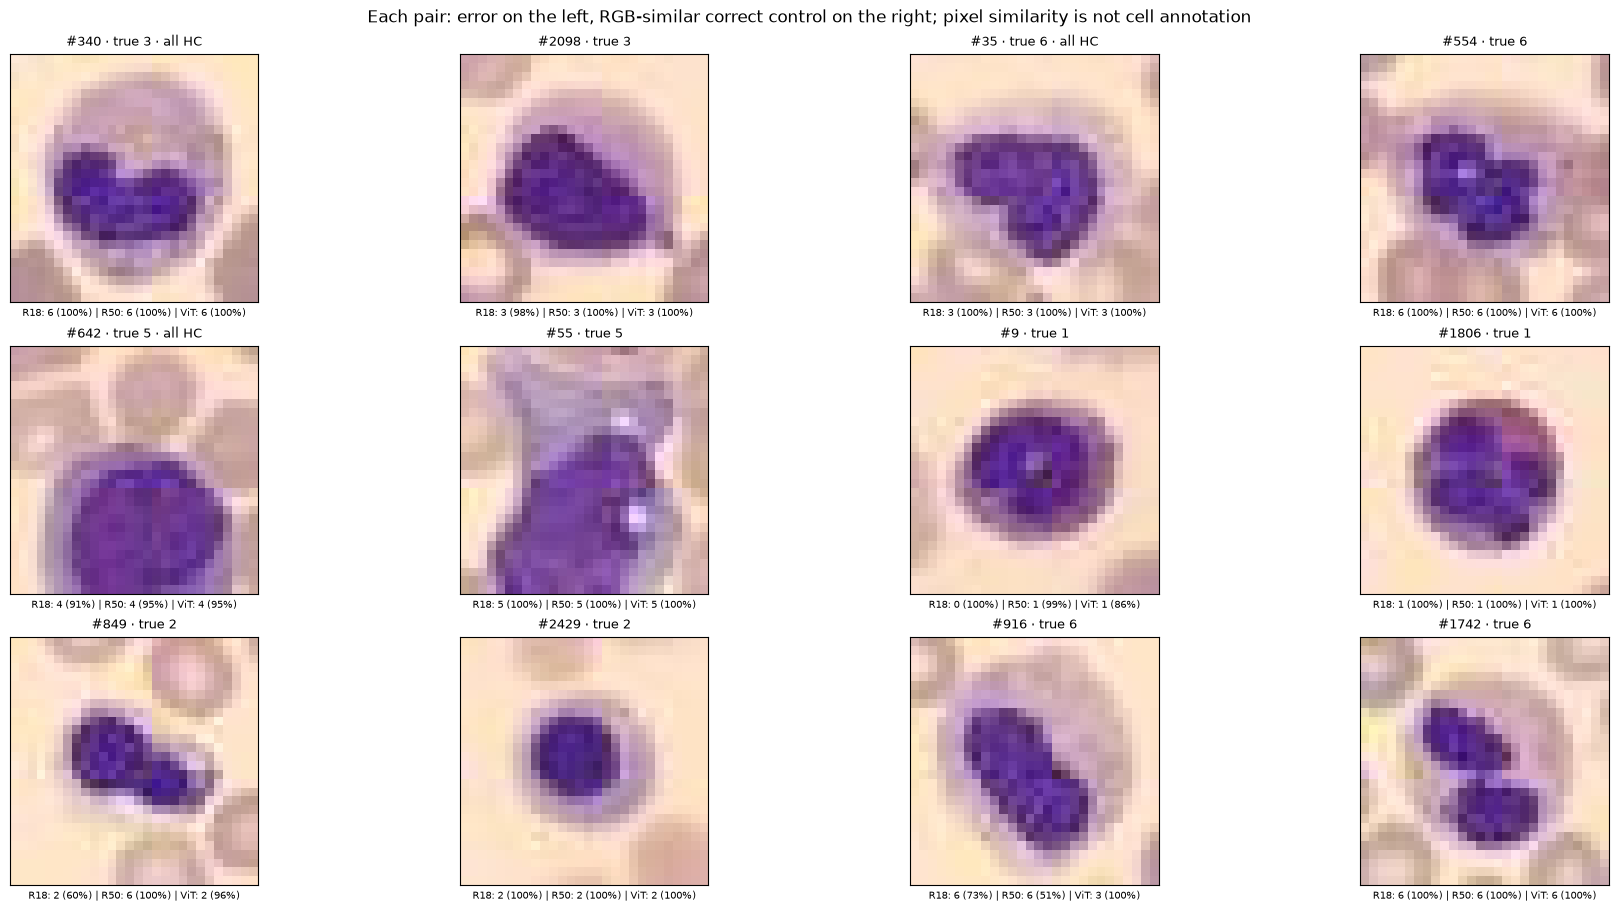

In [39]:
clean = correct.all(0) & (confidence >= threshold).all(0)
largest_classes = np.argsort(-np.bincount(labels[common_hc], minlength=8))[:3]
selected_errors = [common_hc[labels[common_hc] == c][0] for c in largest_classes if (labels[common_hc] == c).any()]
selected_errors += [ids[np.argmax(confidence[m, ids])] for m, ids in enumerate(exclusive_hc) if len(ids)]
gallery_pairs = []
for i in selected_errors:
    allowed = clean & (labels == labels[i])
    assert allowed.any()
    distance = squared + squared[i] - 2 * flat @ flat[i]
    control = np.where(allowed, distance, np.inf).argmin()
    gallery_pairs.append([i, control])
gallery_pairs = np.array(gallery_pairs)
gallery(gallery_pairs.ravel(), 'Each pair: error on the left, RGB-similar correct control on the right; pixel similarity is not cell annotation', columns=4)

The paired images can look similar in broad color and layout while receiving different decisions, as illustrated by cases #340/#2098 and #35/#554. This weakens a simple explanation that every error has an obviously unusual overall appearance. Differences in dark structures are worth investigating, but RGB matching is sensitive to alignment and is not a substitute for expert cell annotation.

## B · Hypotheses: class concentration and image features — error rate per true class; features versus class-matched controls correct and confident in every model

In [40]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
cohorts = [common_hc, *exclusive_hc]
cohort_names = ['All three HC wrong', *[f'Only {name} HC wrong' for name in model_names]]
cohort_effects, cohort_weights = [], []
for ids in cohorts:
    weights = np.zeros(len(labels))
    for c in np.unique(labels[ids]):
        mask = clean & (labels == c)
        assert mask.any()
        weights[mask] = (labels[ids] == c).mean() / mask.sum()
    mean = np.average(features, axis=0, weights=weights)
    std = np.sqrt(np.average((features - mean) ** 2, axis=0, weights=weights))
    cohort_effects.append((features[ids].mean(0) - mean) / np.maximum(std, 1e-12))
    cohort_weights.append(weights)
cohort_effects = np.stack(cohort_effects)

def plot_class_rates():
    fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
    im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
    ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    for m in range(3):
        for c in range(8):
            ax.text(c, m, f'{class_hc_rates[m, c]:.1%} ({class_hc_counts[m, c]}/{class_sizes[c]})', ha='center', fontsize=8)
    fig.colorbar(im, ax=ax, label='Fraction of ≥90%-confident errors within each true class')
    plt.show()

def plot_shared_features():
    fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
    limit = max(np.abs(cohort_effects).max(), 0.01)
    im = ax.imshow(cohort_effects, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
    ax.set(xticks=range(7), xticklabels=feature_names, yticks=range(4),
           yticklabels=[f'{name} (N={len(ids)})' for name, ids in zip(cohort_names, cohorts)])
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
    for row in range(4):
        for col in range(7):
            ax.text(col, row, f'{cohort_effects[row, col]:+.2f}', ha='center')
    fig.colorbar(im, ax=ax, label='Error minus correct control, in control standard deviations')
    plt.show()

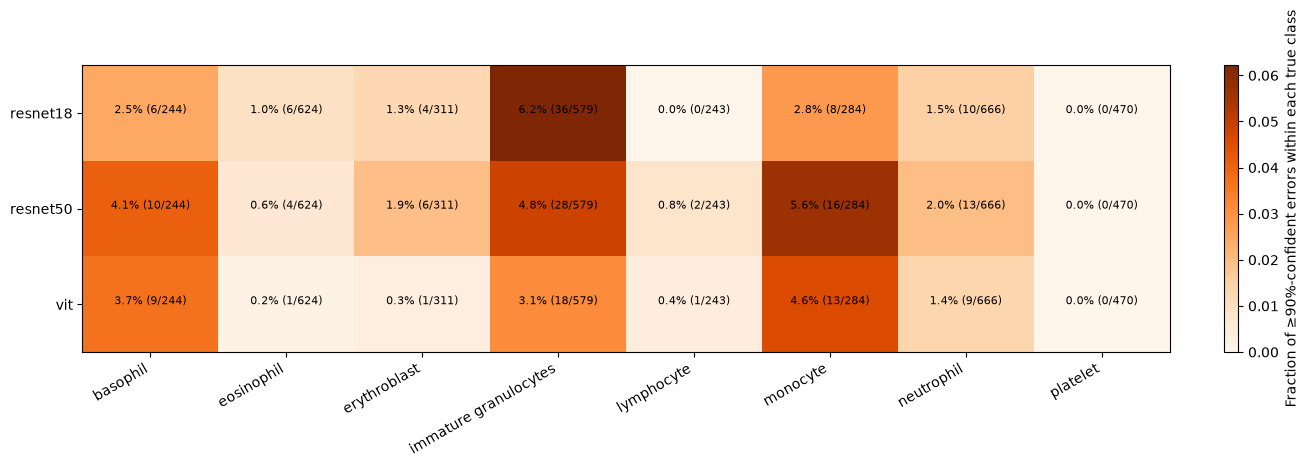

In [41]:
plot_class_rates()

The class-rate view confirms that frequency alone does not explain the error pattern: ResNet18 makes high-confidence errors on 6.22% of immature-granulocyte images, compared with 2.05% overall. Monocytes have the highest rates for ResNet50 and ViT, at 5.63% and 4.58%. The different rankings suggest checkpoint-specific weaknesses rather than one universally difficult class.

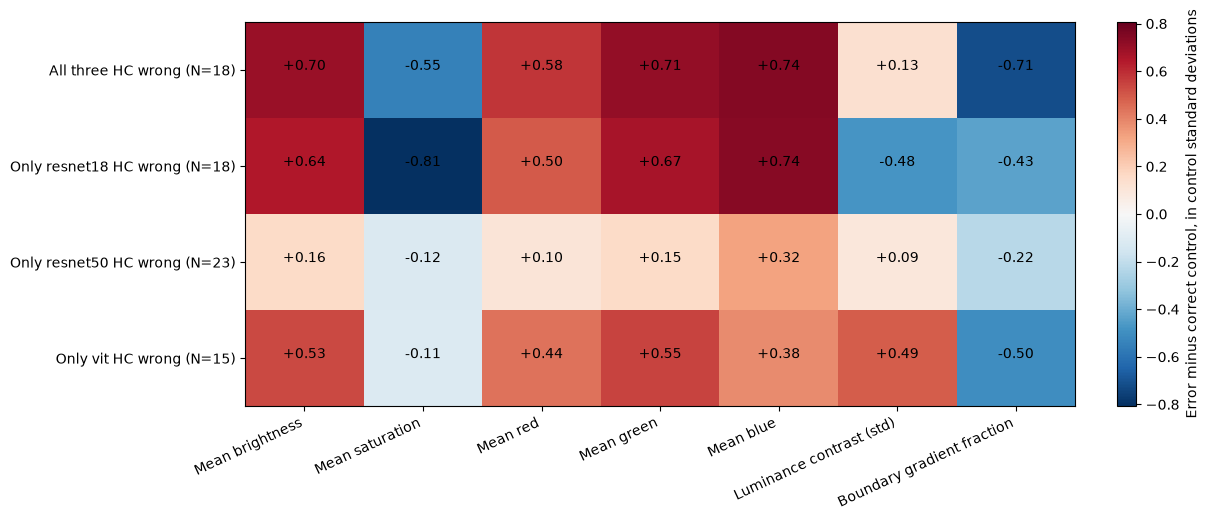

In [42]:
plot_shared_features()

The shared high-confidence errors are brighter (+0.70 control SD), have higher blue values (+0.74 SD) and lower saturation (−0.55 SD) than class-matched confident correct controls. The exclusive groups do not show identical feature profiles, so there is no single appearance signature for all failures. These differences motivate testing brightness and staining-related changes separately, while controlling for their correlation and checking new errors in correct images.

## C · Linking errors to stability — same brightness and translation levels; all HC errors versus RGB-near correct ≥90%-confident same-class controls; a changed decision is not necessarily a correction

In [43]:
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    followup_levels = {kind: saved[f'levels_{kind}'] for kind in ['brightness', 'translation']}
followup = dict(model_names=model_names, threshold=threshold, common_wrong=common_wrong, common_hc=common_hc,
                gallery_pairs=gallery_pairs, class_sizes=class_sizes, class_hc_counts=class_hc_counts,
                cohort_names=cohort_names, cohort_effects=cohort_effects, cohort_weights=np.stack(cohort_weights),
                cohort_roles=['HC errors', 'correct HC controls'], checkpoints=checkpoints)
for m, ids in enumerate(error_ids):
    distance = np.maximum(squared[:, None] + squared[ids][None] - 2 * flat @ flat[ids].T, 0)
    allowed = correct[m, :, None] & (confidence[m, :, None] >= threshold) & (labels[:, None] == labels[ids])
    assert allowed.any(0).all()
    controls = np.where(allowed, distance, np.inf).argmin(0)
    selected = np.stack((ids, controls))
    base, scores = predict(m, images[selected.ravel()])
    base = base.reshape(2, len(ids), 8)
    np.testing.assert_allclose(base, probabilities[m, selected], atol=1e-5, rtol=1e-4)
    original = base.argmax(-1)
    original_probability = base.max(-1)
    followup[f'{model_names[m]}_ids'] = selected
    followup[f'{model_names[m]}_exclusive_hc'] = exclusive_hc[m]
    followup[f'{model_names[m]}_baseline'] = base
    followup[f'{model_names[m]}_baseline_logits'] = scores.reshape(2, len(ids), 8)
    print(f'{model_names[m]}: {len(ids)} errors, {len(np.unique(controls))} unique controls; mean baseline confidence {original_probability[0].mean():.1%} / {original_probability[1].mean():.1%}')
    for col, (kind, values) in enumerate(followup_levels.items()):
        results, logits = [], []
        for value in values:
            changed = []
            for image in images[selected.ravel()]:
                pil = Image.fromarray(image)
                out = ImageEnhance.Brightness(pil).enhance(float(value)) if kind == 'brightness' else pil.transform(
                    pil.size, Image.Transform.AFFINE, (1, 0, -float(value), 0, 1, 0),
                    resample=Image.Resampling.BILINEAR, fillcolor=(128, 128, 128))
                changed.append(np.asarray(out))
            p, scores = predict(m, np.stack(changed))
            results.append(p.reshape(2, len(ids), 8))
            logits.append(scores.reshape(2, len(ids), 8))
        p = np.stack(results, axis=1)
        delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
        followup[f'{model_names[m]}_{kind}'] = p
        followup[f'{model_names[m]}_{kind}_logits'] = np.stack(logits, axis=1)
        print(f'{model_names[m]} {kind}: mean probability drop for errors {-delta[0].mean():.3f}, controls {-delta[1].mean():.3f}')
followup.update({f'levels_{kind}': values for kind, values in followup_levels.items()})
np.savez_compressed('predictions/high_confidence_followup.npz', **followup)

def plot_targeted_followup():
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), layout='constrained')
    for m, model in enumerate(model_names):
        ids = followup[f'{model}_ids'][0]
        base = followup[f'{model}_baseline']
        original, original_probability = base.argmax(-1), base.max(-1)
        for col, (kind, values) in enumerate(followup_levels.items()):
            p = followup[f'{model}_{kind}']
            delta = np.take_along_axis(p, original[:, None, :, None], axis=-1)[..., 0] - original_probability[:, None]
            for role, name in enumerate(['HC errors', 'Correct HC controls']):
                axes[m, col].plot(values, delta[role].mean(-1), 'o-', label=name)
            axes[m, col].axhline(0, color='gray', ls='--')
            axes[m, col].set(title=f'{model_names[m]} · {kind} · N={len(ids)} pairs',
                              xlabel=kind, ylabel='Change in p(original class)')
            axes[m, col].grid(alpha=0.2)
    axes[0, 0].legend()
    fig.suptitle('Targeted follow-up using stability levels: errors versus class-matched correct decisions')
    plt.show()

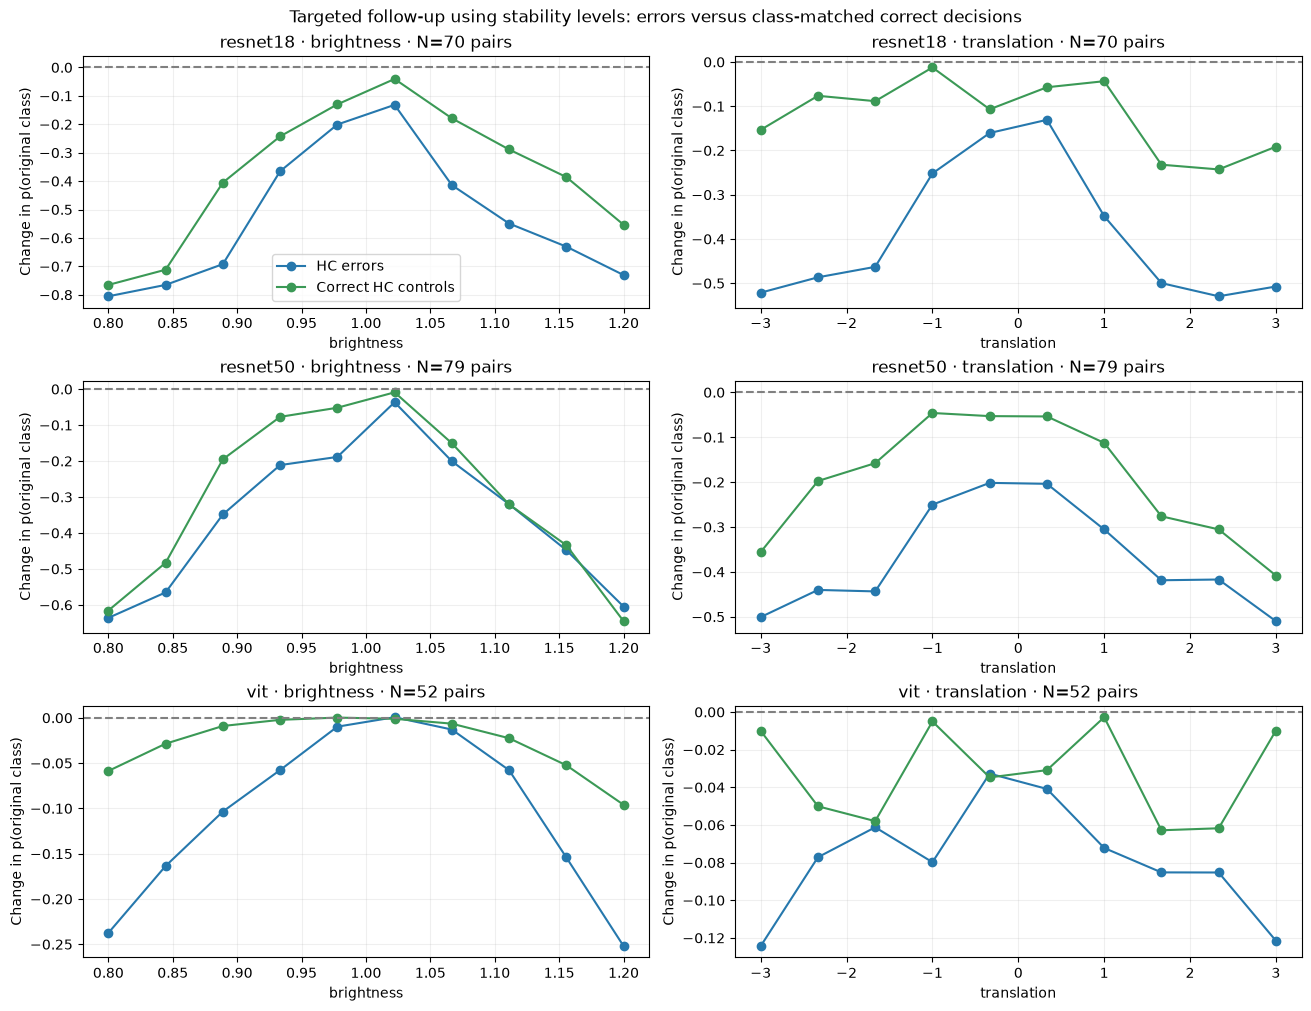

In [44]:
plot_targeted_followup()

The high-confidence wrong decisions lose more original-class probability than the correct controls under both tested operations in all three models. For ResNet18, the mean translation drop is 39.0 percentage points for errors versus 12.0 for controls, despite both groups starting above the 90% threshold. Transformation response may therefore be worth testing as an additional warning signal, but the controls start with higher average confidence and a changed prediction is not necessarily a correction.

## Findings

- **Shared errors (gallery A):** All three models misclassify 39 images, and 18 of these receive ≥90% confidence from every model. On these 18 images, all models predict the same wrong class; half confuse immature granulocytes with neutrophils or vice versa. This shows that agreement between confident models is not a reliable correctness check for these cases. Shared visual ambiguity or shared data-related weaknesses are possible explanations, but distinguishing them requires an independent review of the images and labels.
- **Class dependence (heatmap B):** ResNet18 makes high-confidence errors on 6.22% of immature-granulocyte images, compared with 2.05% of all test images. Monocytes have the highest rates for ResNet50 and ViT: 5.63% and 4.58%, compared with overall rates of 2.31% and 1.52%. These rates use the number of test images within each true class as the denominator, so the pattern is not simply caused by some classes having more images. The results suggest class-specific weaknesses, but the different rankings show that no single class explains all three models' errors.
- **Image features (heatmap B):** Compared with class-matched correct controls, the 18 shared high-confidence errors are brighter (+0.70 control SD), have higher blue values (+0.74 SD) and lower saturation (−0.55 SD). The matched image pairs nevertheless show similar broad color regions despite different decisions, so these averages do not provide a rule that separates every error from a correct prediction. Brightness, blue intensity and saturation are related, and this descriptive comparison cannot identify which feature matters independently. A useful next test is to vary brightness and saturation separately on new same-class image pairs, while checking whether changes also damage initially correct predictions.
- **Stability link (curves C):** Across the tested brightness and translation levels, all three models lose more probability for their original wrong decisions than for their original correct decisions on matched controls. For ResNet18, the mean drop across ten translation levels is 39.0 percentage points for errors versus 12.0 for controls. Thus, high confidence on the unchanged image can coexist with sensitivity to small transformations, making transformation response worth testing as an additional warning signal. However, a probability drop or label switch is not necessarily a correction, and the controls start with slightly higher confidence; these results do not yet establish a reliable error detector.

**Limits:** There are only 18 shared high-confidence errors, so their feature averages may be sensitive to individual images. Controls match class and confidence threshold, not exact confidence, and some controls are reused rather than providing independent comparisons. ResNet18 and ViT process resized 224×224 inputs while ResNet50 uses 28×28, with different resizing methods; the comparisons therefore concern these checkpoints and pipelines, not architectures alone. Image modifications may not preserve the true label, and hypotheses selected from these test results need confirmation on new images.